# ¿Cuánto aviso nos da un río? · 02 — Modelos de caudal con información local: Tamshiyacu (Ucayali–Amazonas)

**Curso:** Ciencia de Datos Ambientales (CDA) · Universidad de Ingeniería y Tecnología (UTEC) · Proyecto Integrador

**Equipo:** 

- Luis Angel Cupe Espinoza
- Yely Lanasca Justiniano 
- Lia Kim Alcantara Tineo 
- Mayra Madelyn Marzano Mejia 
- María Fernanda Torres Carbajal 

**Protocolo:** común a todo el estudio (`comun.py`; identificado como `v4` en el código y en las salidas). La fecha de ejecución y las versiones de software se imprimen en la celda de configuración.

**Lugar en el estudio:** este cuaderno responde la pregunta **P1** —hasta qué horizonte se pronostica bien la magnitud del caudal con la información local de la estación— en Tamshiyacu (Ucayali–Amazonas, vertiente amazónica). Forma parte de una secuencia única: Racarumi (01), comparación de estaciones (03), anticipación de crecidas (04), estaciones aguas arriba (05), lluvia de la cuenca (06), Chronos-2 (07), comparación integrada y selección final (08) y síntesis (09).

**Sobre el periodo de prueba:** las reglas de selección se fijaron antes de la evaluación final, pero el periodo de prueba (2016–fin) se consultó durante el desarrollo del proyecto, al decidir qué modelos conservar. Sus cifras se leen como la evaluación de un protocolo congelado, no como una confirmación totalmente independiente.

---

## 0. Objetivo y decisiones de diseño

### 0.1 Pregunta
> **¿Cuál es el horizonte útil del pronóstico diario del caudal de Tamshiyacu y cómo varía entre modelos, periodos y condiciones de caudal?**

**Estación:** Tamshiyacu (PE_240103), río Amazonas aguas abajo de la confluencia del Marañón y el Ucayali (~720 000 km²). El EDA la clasificó como **apta con reservas** (41.1 años, 0.46 % de vacíos) por **41 escalones de nivel** el 1 de enero y el 1 de setiembre entre 1985 y 2014; desde 2015 su registro es coherente. Se excluyen las muestras cuya ventana cruza un escalón (la prueba no tiene ninguno) y la sección 12 estudia la sensibilidad a esos registros.

### 0.2 Qué se pronostica y con qué
- **Objetivo:** caudal observado diario Q(t + h) en m³/s, para **h = 1 a 30 días**, emitido el día t (pronóstico directo: cada horizonte se estima con la información disponible en t, sin realimentar pronósticos).
- **Entradas:** caudales observados de la propia estación de t − 29 a t (30 días) y la **época del año** (seno y coseno del día del año, información estacional adicional, igual para todos los modelos). Sin precipitación ni caudal simulado.
- **Datos:** serie observada depurada del EDA. Vacíos ≤ 3 días se interpolan **solo en las entradas** y solo entre días observados ≤ t (se exige Q(t) observado); los objetivos nunca se imputan. Una emisión se evalúa solo si sus 30 objetivos están observados: todos los modelos y horizontes usan el mismo conjunto de emisiones.
- **Disponibilidad operativa:** se supone que el caudal medio del día t está disponible al emitir. Un uso real tendría que restar la latencia de publicación.

### 0.3 Protocolo (fijado antes de ver la prueba)
| Paso | Decisión |
|---|---|
| División temporal | Entrenamiento: inicio–2008 · Validación: 2009–2015 · Prueba: 2016–fin. Ningún objetivo de un bloque cruza al siguiente. |
| Preparación sin información futura | ε de log(Q + ε), umbral de escalones, P95 y estandarizaciones se calculan **solo con entrenamiento**; con entrenamiento + validación se reentrena sin recalcularlos. |
| Referencias | Persistencia y climatología del día del año (31 días). La climatología usa los mismos años que el modelo en cada fase. |
| Modelos (6) | Regresión lineal múltiple, Random Forest, XGBoost, KNN, MLP y LSTM, más el **combinado por horizonte**. Todos aprenden el **cambio logarítmico** respecto a hoy. Entradas: 30 días + calendario (la LSTM, como secuencia); **KNN elige con la validación cuántos días usa en la distancia (3, 7, 15 o 30)**. La comparación es entre configuraciones ajustadas por modelo, no entre algoritmos con entradas idénticas. Random Forest y MLP aprenden los objetivos **estandarizados por horizonte** (como la LSTM), para que todos los horizontes pesen lo mismo en su ajuste. |
| Validación en dos bloques | **Calibración 2009–2011** (solo estima la corrección de retransformación de Duan) y **selección 2012–2015** (solo compara candidatos). Ninguna emisión de calibración tiene objetivos en el bloque de selección (separación ≥ 30 días): cada pronóstico comparado usa solo factores estimados con el pasado. |
| Ajuste | Mallas predefinidas (1 a 40 combinaciones por modelo, registradas) evaluadas con el NSE medio de los 30 horizontes en el bloque de selección. Sin particiones aleatorias: XGBoost y MLP sin parada interna; iteraciones y épocas como hiperparámetros. La LSTM se detiene con un bloque **distinto** (2005–2008, entrenando hasta 2004) y luego se reentrena con todo el entrenamiento. |
| Semillas | Random Forest, XGBoost, MLP y LSTM se repiten con 3 semillas predefinidas; el pronóstico es su promedio y se informa la variabilidad entre semillas. |
| Selección (regla fijada antes de evaluar) | 1) Mejor = mayor NSE medio en el bloque de selección. 2) Diferencia de cada candidato con el mejor por bootstrap **pareado** por meses (IC 90 %): **equivalente** si el IC cabe en ±0.01 de NSE, **peor** si queda bajo 0, **inconcluso** en otro caso. 3) **Seleccionado = el más simple** entre el mejor y sus equivalentes (lineal < KNN < Random Forest < XGBoost < MLP < LSTM). Combinado por horizonte: para cada h, el modelo con mejor NSE en ese h en el bloque de selección (no compite: su NSE de selección es optimista por construcción). La prueba no se usa para decidir. |
| Retransformación en prueba | Factor de Duan estimado con los residuos de toda la validación del modelo entrenado hasta 2008 (fuera de muestra y anterior a la prueba) y **transferido** al modelo reentrenado con 2009–2015; no se presume perfecto después del reentrenamiento (la sección 5.3 muestra cuánto cambia la prueba sin él). |
| Métricas (m³/s) | MAE, RMSE, NSE, KGE, PBIAS y **habilidad** = 1 − MSE(modelo)/MSE(referencia). |

### 0.4 Horizonte útil
| Nombre | Definición | Uso |
|---|---|---|
| **H (definición principal)** | Mayor h consecutivo desde 1 con NSE > 0 y habilidad > 0 frente a la persistencia **y** a la climatología. Si h = 1 falla, H = 0 | Se aplica igual a la prueba y a cada réplica bootstrap |
| **H cota 95 %** | min(H, percentil 5 de H en 1 000 réplicas del bootstrap conjunto por bloques de un mes) | **Cifra que se usa en las conclusiones** |
| Distribución de H | Percentiles 5, 50 y 95 y P(H ≥ 30) | Incertidumbre del horizonte completo |
| H marginal estricto | Exige el límite inferior de cada IC 95 % **marginal** > 0 | Complementario; los IC por horizonte no forman una banda simultánea |
| NSE ≥ 0.5 hasta | Mayor h consecutivo con NSE ≥ 0.5 | Complementario; no es una definición de utilidad operativa |

H = 30 significa **"30 o más"**: el límite no se encontró en el rango evaluado. Un horizonte útil para estimar la **magnitud** no implica avisar un **nuevo** cruce del P95 con esa anticipación; eso se evalúa en `04_Anticipacion_Crecidas.ipynb`.

---
## 1. Configuración
Librerías, semillas y rutas relativas. Las funciones de datos, métricas, modelos y verificación están en `comun.py`, de modo que las dos estaciones se modelan exactamente con el mismo método. Antes de modelar se ejecuta `pruebas_protocolo.py` (sin información futura en las entradas ni en la retransformación, bloques sin solape, regla de selección): si una comprobación falla, el cuaderno se detiene.

In [1]:
import os, subprocess, sys, warnings
from datetime import datetime
from pathlib import Path
import json, platform, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, torch, xgboost

import comun as C

%matplotlib inline
warnings.filterwarnings('ignore')
np.random.seed(C.SEMILLA)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

RAPIDO = os.environ.get('CDA_RAPIDO') == '1'          # solo para probar el código: mallas mínimas
if RAPIDO:
    C.MALLAS = {k: {kk: vv[:1] for kk, vv in v.items()} for k, v in C.MALLAS.items()}
    C.SEMILLAS = C.SEMILLAS[:1]
B = 50 if RAPIDO else 1000

ESTACION = 'Tamshiyacu'
RUTA_SAL = C.ruta_salidas() / ESTACION.lower()          # modo rápido: salidas_rapido/ (nunca se mezcla con la ejecución final)
RUTA_FIG, RUTA_TAB = RUTA_SAL / 'figuras', RUTA_SAL / 'tablas'
for r in (RUTA_FIG, RUTA_TAB):
    r.mkdir(parents=True, exist_ok=True)

L = C.L_VENTANA
H = len(C.HORIZONTES)
H_CLAVE = [1, 2, 3, 5, 7, 10, 15, 20, 30]
MODELOS = list(C.MODELOS)
COMB = C.COMB
COLOR = C.COLOR
FUENTE = 'Fuente: CAMELS-PE v1.0.1 (SENAMHI), caudal observado depurado del EDA'
T_INICIO = time.time()

print(f"Ejecutado: {datetime.now():%Y-%m-%d %H:%M} | protocolo {C.VERSION}" + (' | MODO RÁPIDO (no usar sus cifras)' if RAPIDO else ''))
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"xgboost {xgboost.__version__} | torch {torch.__version__}")
C.asegurar_camels(); print('CAMELS-PE disponible')
# Comprobaciones automáticas del protocolo (información futura, bloques, regla de selección): se detiene si alguna falla
print(subprocess.run([sys.executable, 'pruebas_protocolo.py'], capture_output=True, text=True, check=True).stdout.splitlines()[-1])

Ejecutado: 2026-11-18 02:34 | protocolo v4
Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | xgboost 3.1.2 | torch 2.14.1+cu130
CAMELS-PE disponible


17 comprobaciones correctas


---
## 2. Datos, inventario de muestras y división temporal
Cada día de emisión t es una muestra: su ventana de 30 días de caudal observado (m³/s, con los errores detectados en el EDA como NaN) y sus 30 objetivos, Q(t + 1) … Q(t + 30). ε y el umbral de escalones de nivel se fijan **con el entrenamiento**. El inventario registra cuántas fechas se descartan y por qué (exigir los 30 objetivos observados reduce el conjunto evaluado), y la serie se divide en entrenamiento, validación (calibración y selección) y prueba.
**Por qué:** ningún parámetro de preparación debe depender de años reservados para evaluar, y la base debe ser trazable.

In [2]:
q, info = C.cargar_serie(ESTACION)
EPS = C.eps_entrenamiento(q)
esc = C.escalones(q)
m = C.construir_muestras(q, L=L, H=H, esc=esc, eps=EPS)
p = C.particion(m)
VC = C.ValidacionCausal(m, p['val'])
P95 = float(np.nanpercentile(q.loc[:C.FIN_ENTRENAMIENTO], 95))

print(f"Archivo: {info['archivo']} | estación {info['gid']}")
print(f"Registro: {info['inicio']:%Y-%m-%d} a {info['fin']:%Y-%m-%d} | área {info['area']:,.1f} km² | vacíos {info['vacios']:.2f} % | "
      f"errores del EDA en NaN: {info['n_eliminados']} | días con caudal 0: {info['ceros']}")
print(f"ε (entrenamiento) = {EPS:,.4f} m³/s | escalones de nivel: {len(esc)}" + (f" ({esc.min():%Y-%m-%d} a {esc.max():%Y-%m-%d})" if len(esc) else ''))
print(f"P95 (entrenamiento) = {P95:,.1f} m³/s (alto: Q > P95)")
inventario = pd.Series({'fechas candidatas': m.info['candidatas'], 'sin Q(t) observado': m.info['sin_Qt'],
                        'ventana con vacío > 3 días': m.info['ventana_incompleta'], 'algún objetivo sin dato': m.info['objetivo_faltante'],
                        'ventana cruza un escalón': m.info['con_escalon'], 'muestras válidas': m.info['validas'],
                        'válidas con entrada interpolada': m.info['con_entrada_interpolada']}, name='fechas')
inventario.to_csv(RUTA_TAB / 'tabla_inventario_muestras.csv')
resumen = pd.DataFrame({
    'periodo de emisión': [f"{m.fechas[v].min():%Y-%m-%d} a {m.fechas[v].max():%Y-%m-%d}" for v in p.values()],
    'muestras': [len(v) for v in p.values()],
    'Q medio (m³/s)': [m.q_t[v].mean() for v in p.values()],
    'días > P95 en t (%)': [100 * (m.q_t[v] > P95).mean() for v in p.values()],
}, index=['Entrenamiento', 'Validación', 'Prueba']).round(1)
resumen.to_csv(RUTA_TAB / 'tabla_division.csv')
bloques_val = pd.Series(VC.resumen(), name='validación')
bloques_val.to_csv(RUTA_TAB / 'tabla_validacion_bloques.csv')
display(inventario.to_frame()); display(bloques_val.to_frame())
resumen

Archivo: CAMELS-PE_v1.0.1/CAMELS-PE/03_timeseries/by_catchment/PE_240103.csv | estación PE_240103
Registro: 1984-09-01 a 2025-12-31 | área 719,664.7 km² | vacíos 0.46 % | errores del EDA en NaN: 0 | días con caudal 0: 0
ε (entrenamiento) = 301.4612 m³/s | escalones de nivel: 41 (1985-01-01 a 2014-01-01)
P95 (entrenamiento) = 47,602.8 m³/s (alto: Q > P95)


,fechas
fechas candidatas,15038
sin Q(t) observado,69
ventana con vacío > 3 días,157
algún objetivo sin dato,182
ventana cruza un escalón,2419
muestras válidas,12211
válidas con entrada interpolada,143


,validación
calibración,2009-01-30 a 2011-12-01
muestras calibración,800
selección,2012-01-01 a 2015-12-01
muestras selección,1195
excluidas por la separación de 30 días,30


,periodo de emisión,muestras,Q medio (m³/s),días > P95 en t (%)
Entrenamiento,1984-09-30 a 2008-12-01,6904,32100.4,6.4
Validación,2009-01-30 a 2015-12-01,2025,32423.3,12.6
Prueba,2016-01-01 a 2025-12-01,3252,29271.7,2.4


**Interpretación:**
- **Registro:** 1984-09-01 a 2025-12-31 (≈ 720 000 km²), con 0.46 % de vacíos, ningún valor eliminado por el EDA y ningún día con caudal 0. Hay **41 escalones de nivel** entre 1985 y 2014.
- **Parámetros fijados con el entrenamiento:** ε = 301.5 m³/s y P95 = 47 603 m³/s.
- **Inventario:** de 15 038 fechas candidatas se descartan 69 sin Q(t) observado, 157 con un vacío de más de 3 días en la ventana, 182 con algún objetivo sin dato y **2 419 cuya ventana cruza un escalón**; quedan **12 211 muestras** (143 con algún día interpolado en la entrada).
- **División:** 6 904 muestras de entrenamiento, 2 025 de validación y 3 252 de prueba. La validación se parte en **calibración** (2009-01-30 a 2011-12-01, 800 emisiones) y **selección** (2012-01-01 a 2015-12-01, 1 195); 30 emisiones quedan fuera por la separación de 30 días. El 6.4 %, 12.6 % y 2.4 % de los días de cada bloque supera el P95: la prueba tiene pocos días altos.

**Figura 1.** Serie observada con los tres bloques, el umbral P95 y los escalones de nivel (si los hay).

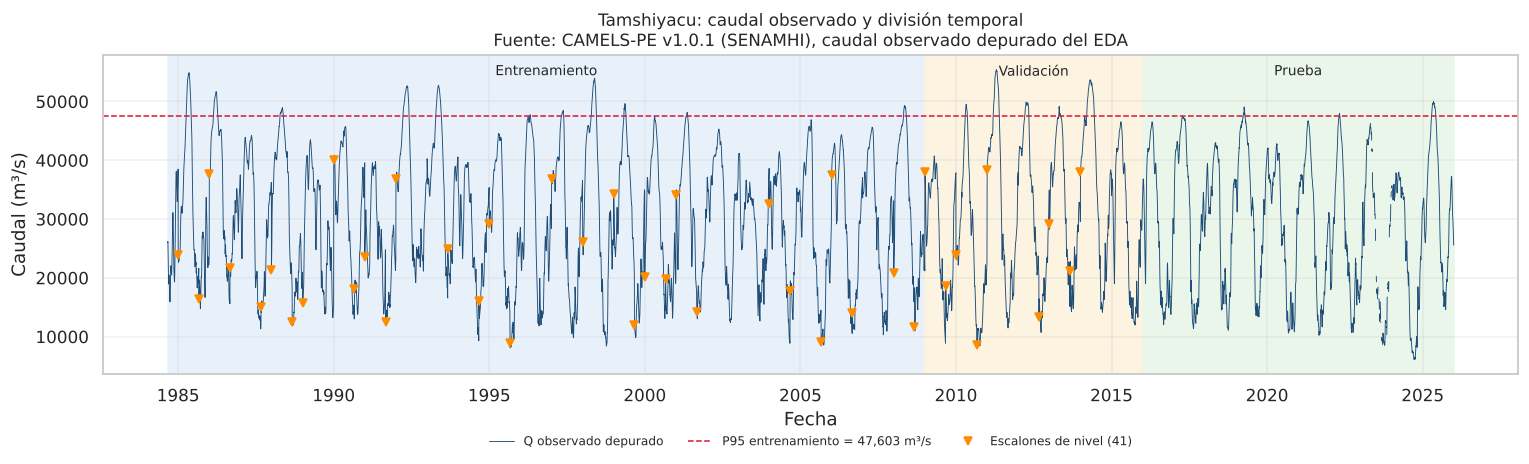

In [3]:
fig, ax = plt.subplots(figsize=(14, 4.4))
ax.plot(q.index, q, color='#1f4e79', lw=0.6, label='Q observado depurado')
lims = [(q.index.min(), pd.Timestamp(C.FIN_ENTRENAMIENTO), 'Entrenamiento', '#e8f1fa'),
        (pd.Timestamp(C.FIN_ENTRENAMIENTO), pd.Timestamp(C.FIN_VALIDACION), 'Validación', '#fdf3e1'),
        (pd.Timestamp(C.FIN_VALIDACION), q.index.max(), 'Prueba', '#eaf6ea')]
for a, b, et, col in lims:
    ax.axvspan(a, b, color=col, zorder=0)
    ax.text(a + (b - a) / 2, 0.97, et, transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=9)
ax.axhline(P95, color='crimson', ls='--', lw=1, label=f'P95 entrenamiento = {P95:,.0f} m³/s')
if len(esc):
    ax.plot(esc, q.reindex(esc), 'v', color='darkorange', ms=5, label=f'Escalones de nivel ({len(esc)})')
ax.set_ylabel('Caudal (m³/s)'); ax.set_xlabel('Fecha')
ax.set_title(f'{ESTACION}: caudal observado y división temporal\n{FUENTE}', fontsize=11)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), fontsize=8, ncol=3, frameon=False); ax.grid(True, alpha=0.3)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig01_serie_division.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:** el Amazonas en Tamshiyacu tiene un ciclo anual lento y regular: aguas bajas de 10 000–20 000 m³/s hacia setiembre–octubre y crecientes de 40 000–50 000 m³/s hacia abril–mayo, que duran semanas. Los escalones de nivel (1985–2014) aparecen el 1 de enero y el 1 de setiembre; desde 2015 el registro es coherente.

---
## 3. Métodos de referencia
Todo modelo se mide frente a dos referencias sin aprendizaje: la **persistencia** (Q(t + h) = Q(t)) y la **climatología** del día del año, en los 30 horizontes de la prueba. La climatología de la evaluación final usa entrenamiento + validación, los mismos años con que se reentrenan los modelos.

In [4]:
CLIM_E = C.climatologia(q, hasta=C.FIN_ENTRENAMIENTO)
CLIM_F = C.climatologia(q, hasta=C.FIN_VALIDACION)
idx_p = p['pru']
OBS = m.q_obs[idx_p]
PERS = C.pred_persistencia(m, idx_p)
CLIM = C.pred_climatologia(m, idx_p, CLIM_F)
ref = pd.DataFrame({'NSE persistencia': [C.nse(OBS[:, j], PERS[:, j]) for j in range(H)],
                    'NSE climatología': [C.nse(OBS[:, j], CLIM[:, j]) for j in range(H)],
                    'MAE persistencia': [C.mae(OBS[:, j], PERS[:, j]) for j in range(H)],
                    'MAE climatología': [C.mae(OBS[:, j], CLIM[:, j]) for j in range(H)]},
                   index=pd.Index(C.HORIZONTES, name='h'))
ref.to_csv(RUTA_TAB / 'tabla_referencias_prueba.csv')
cruce = ref.index[ref['NSE persistencia'] < ref['NSE climatología']]
print('La climatología supera a la persistencia (NSE) desde h =', int(cruce.min()) if len(cruce) else '> 30')
ref.loc[H_CLAVE].round(3)

La climatología supera a la persistencia (NSE) desde h = 18


,NSE persistencia,NSE climatología,MAE persistencia,MAE climatología
h,,,,
1,0.998,0.786,360.016,4113.417
2,0.993,0.785,690.858,4115.283
3,0.986,0.785,997.800,4117.100
5,0.966,0.785,1550.559,4120.522
7,0.942,0.785,2059.060,4123.083
10,0.900,0.785,2753.307,4125.138
15,0.821,0.786,3761.101,4123.580
20,0.734,0.787,4663.353,4117.386
30,0.532,0.792,6344.960,4085.693


**Interpretación:**
- **La persistencia es muy buena hasta 2 semanas:** NSE 0.998 a 1 día, 0.942 a 7 días, 0.900 a 10 días, 0.821 a 15 días y 0.532 a 30 días.
- **La climatología tiene NSE ≈ 0.79** y supera a la persistencia recién desde los **18 días**: el estado actual del río informa durante semanas.

---
## 4. Ajuste de hiperparámetros (validación temporal)
Cada combinación de la malla de un modelo se entrena con el entrenamiento (hasta 2008) y pronostica toda la validación; la corrección de Duan se estima **solo con 2009–2011** y el criterio es el NSE medio de los 30 horizontes en **2012–2015** (m³/s).
- **XGBoost:** sin parada temprana. El número de árboles (100, 200 o 400) se evalúa por etapas con un solo ajuste: los primeros k árboles de un ajuste de 400 son idénticos a un ajuste de k árboles.
- **KNN:** además de k y la ponderación, elige cuántos días de historia usa la distancia (3, 7, 15 o 30), porque muchos rezagos redundantes pueden empeorar la búsqueda de análogos.
- **LSTM:** para cada combinación entrena hasta 2004 y detiene con 2005–2008; luego reentrena con todo el entrenamiento esas épocas y se compara en validación.
**Presupuesto de búsqueda:** entre 1 y 40 combinaciones por modelo (tabla siguiente); se registran configuraciones, segundos y semilla. Los presupuestos son distintos entre modelos: las diferencias pequeñas no se atribuyen solo al algoritmo.

In [5]:
X, nombres = C.matriz_tabular(m)
ie, iv = p['ent'], p['val']
OBS_V = VC.obs_sel                                        # observado del bloque de selección (2012–2015)
a_q_val = VC.a_q                                          # Duan de 2009–2011 aplicado a 2012–2015

filas, mejores = [], {}
for nombre in MODELOS:
    if nombre == 'LSTM':
        continue
    sub = C.ajustar_malla(nombre, X[ie], m.y[ie], X[iv], a_q_val, OBS_V)
    filas += sub
    mejor = max(sub, key=lambda f: f['NSE_val'])
    mejores[nombre] = json.loads(mejor['parametros'])
    print(f"{nombre:22s} {len(sub):3d} combinaciones | mejor NSE medio selección = {mejor['NSE_val']:.4f} con {mejores[nombre]}")

ie_in = ie[m.fechas[ie] + pd.Timedelta(days=H) <= pd.Timestamp(C.FIN_PARADA)]
ie_par = ie[m.fechas[ie] > pd.Timestamp(C.FIN_PARADA)]
for params in C.combinaciones(C.MALLAS['LSTM']):
    t0 = time.time()
    lp = C.LSTMProtocolo(m, ie_in, ie_par, **params).ajustar(ie)
    nv = C.nse_medio(a_q_val(lp.predecir(iv)), OBS_V)
    filas.append(dict(modelo='LSTM', parametros=json.dumps({**params, 'epocas': lp.epocas}), NSE_val=nv, segundos=time.time() - t0))
sub = [f for f in filas if f['modelo'] == 'LSTM']
mejor_lstm = json.loads(max(sub, key=lambda f: f['NSE_val'])['parametros'])
mejores['LSTM'] = {k: v for k, v in mejor_lstm.items() if k != 'epocas'}
print(f"{'LSTM':22s} {len(sub):3d} combinaciones | mejor NSE medio selección = {max(f['NSE_val'] for f in sub):.4f} con {mejor_lstm} "
      f"(parada: entrena {len(ie_in):,} muestras, detiene con {len(ie_par):,})")

ajuste = pd.DataFrame(filas)
ajuste['semilla'] = C.SEMILLA
ajuste = ajuste.rename(columns={'NSE_val': 'NSE_seleccion'})
ajuste.to_csv(RUTA_TAB / 'tabla_ajuste_hiperparametros.csv', index=False)
presupuesto = ajuste.groupby('modelo', sort=False).agg(combinaciones=('parametros', 'count'), segundos=('segundos', 'sum'),
                                                       NSE_sel_mejor=('NSE_seleccion', 'max'), NSE_sel_peor=('NSE_seleccion', 'min'))
presupuesto.to_csv(RUTA_TAB / 'tabla_presupuesto_busqueda.csv')
presupuesto.round(3)

Regresión lineal         1 combinaciones | mejor NSE medio selección = 0.9027 con {}


Random Forest            8 combinaciones | mejor NSE medio selección = 0.9317 con {'max_depth': 20, 'min_samples_leaf': 20, 'max_features': 0.3}


XGBoost                 24 combinaciones | mejor NSE medio selección = 0.9354 con {'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 10.0, 'n_estimators': 100}


KNN                     40 combinaciones | mejor NSE medio selección = 0.9304 con {'n_neighbors': 80, 'weights': 'uniform', 'ventana': 7}


MLP                      8 combinaciones | mejor NSE medio selección = 0.9276 con {'hidden_layer_sizes': [128, 64], 'alpha': 0.0001, 'max_iter': 50}


LSTM                     4 combinaciones | mejor NSE medio selección = 0.9223 con {'oculto': 32, 'dropout': 0.2, 'epocas': 27} (parada: entrena 5,738 muestras, detiene con 1,136)


,combinaciones,segundos,NSE_sel_mejor,NSE_sel_peor
modelo,,,,
Regresión lineal,1,0.027,0.903,0.903
Random Forest,8,101.083,0.932,0.927
XGBoost,24,171.134,0.935,0.905
KNN,40,2.001,0.930,0.892
MLP,8,19.866,0.928,0.893
LSTM,4,45.890,0.922,0.908


**Interpretación:**
- **NSE medio en el bloque de selección (2012–2015)**, con la corrección de retransformación estimada en 2009–2011: XGBoost 0.935, Random Forest 0.932, KNN 0.930, MLP 0.928, LSTM 0.922 y regresión lineal 0.903 (mejor configuración de cada uno, semilla 42).
- **Configuraciones elegidas:** XGBoost con profundidad 3, 100 árboles y λ = 10; Random Forest con profundidad 20, hojas de ≥ 20 muestras y 30 % de variables por partición; KNN con 80 vecinos y **7 días** de historia; MLP de dos capas (128 y 64) con 50 épocas; LSTM de 32 unidades, dropout 0.2 y 27 épocas.
- **Presupuesto de búsqueda:** de 1 a 40 combinaciones por modelo (unos 5 minutos en total).

---
## 5. Modelos finales y evaluación en prueba
Pasos de la evaluación final:
1. Con los mejores hiperparámetros, cada modelo se entrena con el entrenamiento y pronostica la validación. En el bloque de selección (2012–2015) el pronóstico usa el factor de Duan de 2009–2011: con él se aplica la **regla de selección** (sección 5.2) y se arma el combinado. Con los residuos de **toda** la validación se estima el factor que se usa en la prueba.
2. Se reentrena con entrenamiento + validación y se evalúa **una sola vez** en prueba. Los modelos estocásticos se repiten con 3 semillas y se promedian.
3. **Combinado por horizonte:** para cada h, el modelo con mejor NSE en ese h en el bloque de selección (no compite en la selección porque su NSE de selección es optimista por construcción).
4. Se guarda también la **mediana pronosticada** (sin factor de Duan) de validación y prueba: es la que usan los avisos (cuaderno 04), que así no dependen de ningún factor estimado.
5. Se registra cuántos pronósticos negativos (posibles por −ε) se recortan a 0.

In [6]:
it = np.concatenate([ie, iv])
PRED, PRED_V, PRED_MED, PRED_MED_V, FACTOR, NSE_VAL, SEM, NEG = {}, {}, {}, {}, {}, {}, {}, {}
for nombre in MODELOS:
    t0 = time.time()
    semillas = C.SEMILLAS if nombre in C.ESTOCASTICOS else [C.SEMILLA]
    yv_s, yp_s = [], []
    for s in semillas:
        if nombre == 'LSTM':
            lp = C.LSTMProtocolo(m, ie_in, ie_par, semilla=s, **mejores['LSTM']).ajustar(ie)
            yv_s.append(lp.predecir(iv))
            yp_s.append(lp.reajustar(it).predecir(idx_p))
        else:
            yv_s.append(C.crear_tabular(nombre, mejores[nombre], s).fit(X[ie], m.y[ie]).predict(X[iv]))
            mod = C.crear_tabular(nombre, mejores[nombre], s).fit(X[it], m.y[it])
            yp_s.append(mod.predict(X[idx_p]))
            if nombre == C.BASE_AUX and s == C.SEMILLA:
                MODELO_AUX = mod                                  # modelo de los análisis auxiliares (secciones 9, 10)
    yv, yp = np.mean(yv_s, 0), np.mean(yp_s, 0)
    FACTOR[nombre] = C.factor_duan(m.y[iv], yv)                 # toda la validación → se aplica en prueba
    PRED_V[nombre] = VC.a_q(yv)                                  # bloque de selección con el factor de 2009–2011
    PRED_MED_V[nombre] = C.a_caudal(m, yv, iv)                   # mediana, toda la validación (avisos)
    PRED_MED[nombre] = C.a_caudal(m, yp, idx_p)                  # mediana, prueba (avisos)
    PRED[nombre], np_neg = C.a_caudal(m, yp, idx_p, FACTOR[nombre], contar=True)
    NEG[nombre] = dict(prueba=np_neg)
    NSE_VAL[nombre] = C.nse_medio(PRED_V[nombre], OBS_V)
    SEM[nombre] = [C.a_caudal(m, y, idx_p, FACTOR[nombre]) for y in yp_s] if len(semillas) > 1 else []
    print(f"{nombre:22s} {len(semillas)} semilla(s) | {time.time() - t0:6.1f} s | factor h=1/7/30: "
          f"{FACTOR[nombre][0]:.3f} / {FACTOR[nombre][6]:.3f} / {FACTOR[nombre][29]:.3f} | negativos recortados: {np_neg}")

SELEC, MEJOR, MAS_ALTO = C.seleccion_pareada(VC.fechas_sel, OBS_V, {n: PRED_V[n] for n in MODELOS}, B=B)
assert SELEC.loc[MEJOR, 'clase'] in ('mejor', 'equivalente')
nse_v_h = pd.DataFrame({n: [C.nse(OBS_V[:, j], PRED_V[n][:, j]) for j in range(H)] for n in MODELOS}, index=C.HORIZONTES)
ELEGIDO = nse_v_h.idxmax(axis=1)
for dic in (PRED, PRED_V, PRED_MED, PRED_MED_V):
    dic[COMB] = np.column_stack([dic[ELEGIDO[h]][:, h - 1] for h in C.HORIZONTES])
TODOS = MODELOS + [COMB]
pd.DataFrame(NEG).T.to_csv(RUTA_TAB / 'tabla_negativos_recortados.csv')
print('\nNSE medio en el bloque de selección:', {k: round(v, 4) for k, v in sorted(NSE_VAL.items(), key=lambda x: -x[1])})
print(f'Mayor NSE medio: {MAS_ALTO} | seleccionado por la regla (más simple entre equivalentes): {MEJOR}')
print('Combinado por horizonte (selección):', ELEGIDO.groupby(ELEGIDO).apply(lambda s: ', '.join(map(str, s.index))).to_dict())

Regresión lineal       1 semilla(s) |    0.0 s | factor h=1/7/30: 1.000 / 1.005 / 1.028 | negativos recortados: 0


Random Forest          3 semilla(s) |   43.4 s | factor h=1/7/30: 1.000 / 1.005 / 1.022 | negativos recortados: 0


XGBoost                3 semilla(s) |   16.0 s | factor h=1/7/30: 1.000 / 1.002 / 1.014 | negativos recortados: 0


KNN                    1 semilla(s) |    0.3 s | factor h=1/7/30: 1.000 / 1.004 / 1.024 | negativos recortados: 0


MLP                    3 semilla(s) |   10.2 s | factor h=1/7/30: 1.000 / 1.000 / 1.006 | negativos recortados: 0


LSTM                   3 semilla(s) |   49.0 s | factor h=1/7/30: 1.000 / 1.003 / 1.012 | negativos recortados: 0



NSE medio en el bloque de selección: {'XGBoost': 0.9354, 'Random Forest': 0.9316, 'KNN': 0.9304, 'MLP': 0.9286, 'LSTM': 0.9237, 'Regresión lineal': 0.9027}
Mayor NSE medio: XGBoost | seleccionado por la regla (más simple entre equivalentes): XGBoost
Combinado por horizonte (selección): {'XGBoost': '1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30'}


In [7]:
TAB = {n: C.tabla_metricas(OBS, PRED[n], PERS, CLIM) for n in TODOS}
largo = pd.concat({n: t for n, t in TAB.items()}, names=['modelo', 'h']).reset_index()
largo.to_csv(RUTA_TAB / 'tabla_metricas_prueba.csv', index=False)
vista = largo[largo['h'].isin([1, 3, 7, 15, 30])].pivot(index='modelo', columns='h', values='NSE').reindex(TODOS)
vista.loc['Persistencia'] = ref.loc[[1, 3, 7, 15, 30], 'NSE persistencia'].values
vista.loc['Climatología'] = ref.loc[[1, 3, 7, 15, 30], 'NSE climatología'].values
vista.columns = [f'NSE h={h}' for h in vista.columns]
vista.insert(0, 'NSE medio selección', pd.Series(NSE_VAL))
vista.round(3)

,NSE medio selección,NSE h=1,NSE h=3,NSE h=7,NSE h=15,NSE h=30
modelo,,,,,,
Regresión lineal,0.903,0.999,0.993,0.963,0.882,0.770
Random Forest,0.932,0.999,0.993,0.969,0.904,0.827
XGBoost,0.935,0.999,0.993,0.968,0.906,0.843
KNN,0.930,0.999,0.993,0.968,0.903,0.831
MLP,0.929,0.999,0.993,0.967,0.900,0.825
LSTM,0.924,0.999,0.991,0.965,0.906,0.849
Combinado por horizonte,NaN,0.999,0.993,0.968,0.906,0.843
Persistencia,NaN,0.998,0.986,0.942,0.821,0.532
Climatología,NaN,0.786,0.785,0.785,0.786,0.792


In [8]:
largo[largo['h'].isin([1, 7, 30])].set_index(['h', 'modelo'])[['NSE', 'KGE', 'MAE', 'RMSE', 'PBIAS', 'hab_pers', 'hab_clim']].round(3)

,,NSE,KGE,MAE,RMSE,PBIAS,hab_pers,hab_clim
h,modelo,,,,,,,
1,Regresión lineal,0.999,0.999,196.781,295.294,0.048,0.639,0.997
7,Regresión lineal,0.963,0.970,1620.621,2171.907,1.123,0.362,0.828
30,Regresión lineal,0.770,0.872,4238.027,5465.646,5.353,0.508,-0.106
1,Random Forest,0.999,0.999,202.880,301.872,0.012,0.623,0.997
7,Random Forest,0.969,0.978,1472.325,2000.387,0.378,0.459,0.854
30,Random Forest,0.827,0.887,3698.265,4744.113,0.985,0.630,0.167
1,XGBoost,0.999,0.999,192.547,290.167,0.019,0.651,0.997
7,XGBoost,0.968,0.975,1490.714,2017.786,0.191,0.449,0.851
30,XGBoost,0.843,0.881,3518.000,4513.624,0.325,0.665,0.246


**Interpretación:**
- **A 1 día** los seis modelos tienen NSE 0.999 (persistencia 0.998). En m³/s la mejora es clara: la habilidad frente a la persistencia es 0.42–0.66.
- **A 7 días** NSE 0.963–0.969 (persistencia 0.942, climatología 0.785); MAE de 1 470–1 620 m³/s frente a 2 060 de la persistencia.
- **A 30 días** NSE 0.770–0.849 (persistencia 0.532, climatología 0.792): todos superan a la climatología **excepto la regresión lineal**.
- **El combinado por horizonte** elige XGBoost en los 30 horizontes, así que es idéntico a XGBoost.
- **Sesgo total pequeño:** PBIAS a 7 días entre −0.2 % y +1.1 %.

**Figura 2.** Desempeño en prueba según el horizonte: (a) NSE de modelos y referencias; (b) habilidad frente a la persistencia; (c) habilidad frente a la climatología.

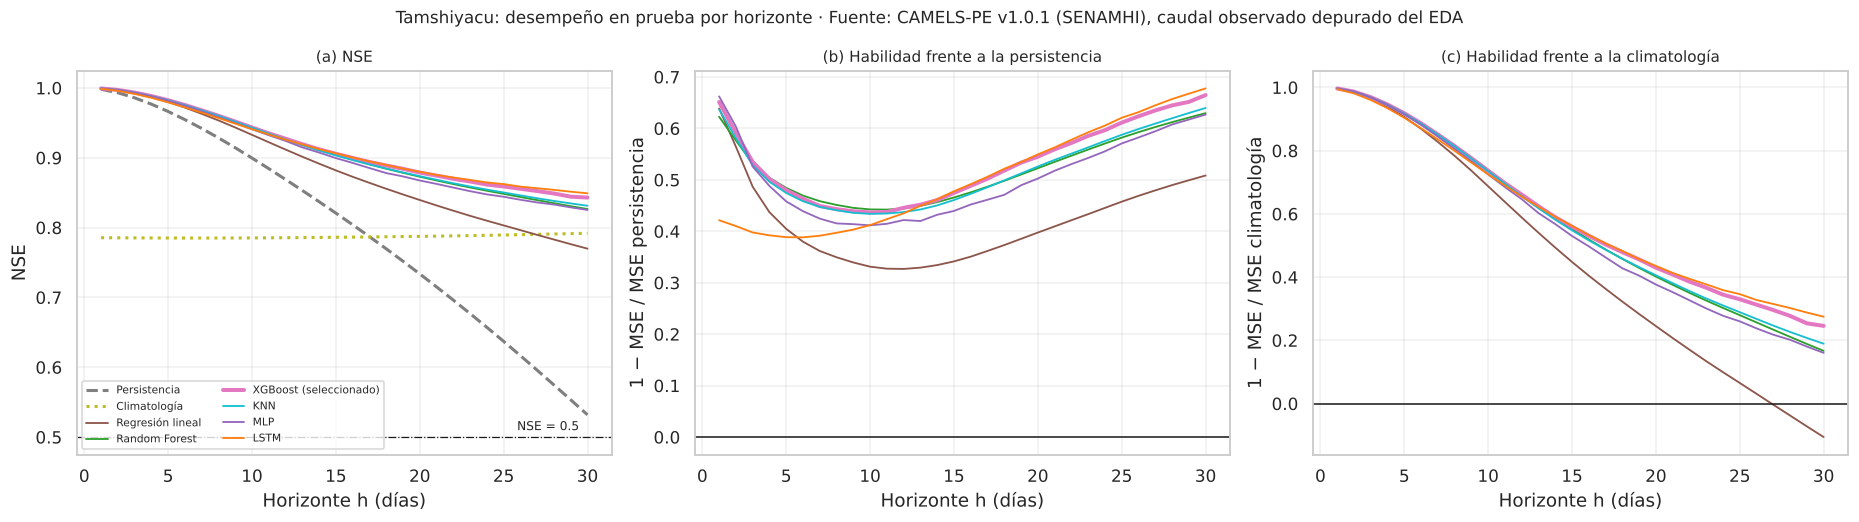

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
hh = np.array(C.HORIZONTES)
ax[0].plot(hh, ref['NSE persistencia'], '--', color=COLOR['Persistencia'], lw=2, label='Persistencia')
ax[0].plot(hh, ref['NSE climatología'], ':', color=COLOR['Climatología'], lw=2, label='Climatología')
for n in MODELOS:
    lw = 2.6 if n == MEJOR else 1.2
    ax[0].plot(hh, TAB[n]['NSE'], color=COLOR[n], lw=lw, label=n + (' (seleccionado)' if n == MEJOR else ''))
    ax[1].plot(hh, TAB[n]['hab_pers'], color=COLOR[n], lw=lw)
    ax[2].plot(hh, TAB[n]['hab_clim'], color=COLOR[n], lw=lw)
ax[0].axhline(0.5, color='k', lw=0.8, ls='-.'); ax[0].text(29.5, 0.51, 'NSE = 0.5', ha='right', fontsize=8)
for a, t in zip(ax, ['(a) NSE', '(b) Habilidad frente a la persistencia', '(c) Habilidad frente a la climatología']):
    a.set_title(t, fontsize=10); a.set_xlabel('Horizonte h (días)'); a.grid(True, alpha=0.3)
for a in ax[1:]:
    a.axhline(0, color='k', lw=1)
ax[0].set_ylabel('NSE'); ax[1].set_ylabel('1 − MSE / MSE persistencia'); ax[2].set_ylabel('1 − MSE / MSE climatología')
ax[0].legend(fontsize=7, loc='lower left', ncol=2)
fig.suptitle(f'{ESTACION}: desempeño en prueba por horizonte · {FUENTE}', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig02_desempeno_horizonte.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:**
- **(a)** Todos los modelos mantienen NSE > 0.96 hasta 7 días y > 0.88 hasta 15; a 30 días se separan: LSTM y XGBoost 0.84–0.85, la regresión lineal 0.77.
- **(b)** La habilidad frente a la persistencia es alta desde el primer día (0.42–0.66) y vuelve a subir a 30 días (0.51–0.68), cuando la persistencia se degrada.
- **(c)** La habilidad frente a la climatología baja de ≈ 1 a 1 día a ≈ 0.85 a 7 días y 0.45–0.56 a 15 días; a 30 días queda entre 0.16 y 0.28, salvo la regresión lineal (−0.11).

### 5.1 Variabilidad entre semillas
En los modelos estocásticos, el pronóstico de cada semilla (con la misma corrección de retransformación) se evalúa por separado y se compara con el promedio que se reporta.

In [10]:
filas_s = []
for n, lista in SEM.items():
    for k, pr in enumerate(lista):
        t = C.tabla_metricas(OBS, pr, PERS, CLIM)
        filas_s.append({'modelo': n, 'semilla': C.SEMILLAS[k], 'H puntual (d)': C.horizonte_util(t),
                        **{f'NSE h={h}': t.loc[h, 'NSE'] for h in (1, 7, 15, 30)}})
    t = TAB[n]
    filas_s.append({'modelo': n, 'semilla': 'promedio (reportado)', 'H puntual (d)': C.horizonte_util(t),
                    **{f'NSE h={h}': t.loc[h, 'NSE'] for h in (1, 7, 15, 30)}})
semillas_tab = pd.DataFrame(filas_s)
semillas_tab.to_csv(RUTA_TAB / 'tabla_semillas.csv', index=False)
semillas_tab.set_index(['modelo', 'semilla']).round(3) if len(semillas_tab) else 'modo rápido: una sola semilla'

H puntual (d)  NSE h=1  NSE h=7  \
modelo           semilla                                                 
Regresión lineal promedio (reportado)             26    0.999    0.963   
Random Forest    42                               30    0.999    0.969   
                 43                               30    0.999    0.969   
                 44                               30    0.999    0.969   
                 promedio (reportado)             30    0.999    0.969   
XGBoost          42                               30    0.999    0.968   
                 43                               30    0.999    0.968   
                 44                               30    0.999    0.968   
                 promedio (reportado)             30    0.999    0.968   
KNN              promedio (reportado)             30    0.999    0.968   
MLP              42                               30    0.999    0.965   
                 43                               30    0.999    0.965   
                 44                               30    0.999    0.966   
                 promedio (reportado)             30    0.999    0.967   
LSTM             42                               30    0.999    0.962   
                 43                               30    0.999    0.964   
                 44                               30    0.999    0.964   
                 promedio (reportado)             30    0.999    0.965   

                                       NSE h=15  NSE h=30  
modelo           semilla                                   
Regresión lineal promedio (reportado)     0.882     0.770  
Random Forest    42                       0.904     0.826  
                 43                       0.905     0.828  
                 44                       0.904     0.825  
                 promedio (reportado)     0.904     0.827  
XGBoost          42                       0.905     0.843  
                 43                       0.906     0.841  
                 44                       0.906     0.844  
                 promedio (reportado)     0.906     0.843  
KNN              promedio (reportado)     0.903     0.831  
MLP              42                       0.893     0.812  
                 43                       0.895     0.821  
                 44                       0.897     0.821  
                 promedio (reportado)     0.900     0.825  
LSTM             42                       0.899     0.836  
                 43                       0.906     0.847  
                 44                       0.904     0.846  
                 promedio (reportado)     0.906     0.849

**Interpretación:**
- **Random Forest y XGBoost son estables entre semillas** (NSE con diferencias ≤ 0.003).
- **Las redes varían algo más:** NSE a 30 días de 0.813 a 0.821 (MLP) y de 0.836 a 0.847 (LSTM). En las tres semillas H puntual es ≥ 30 días.
- **La MLP es estable a 1 día:** con los objetivos estandarizados por horizonte su NSE a 1 día es 0.999 en las tres semillas.

### 5.2 Regla de selección: comparación pareada en el bloque de selección
La regla fijada antes de evaluar (sección 0.3) se aplica a los seis modelos en 2012–2015: diferencia de NSE medio con el de mayor NSE, intervalo del 90 % por bootstrap pareado de meses (las mismas réplicas para todos) y clase (equivalente, peor o inconcluso, con margen ±0.01). El seleccionado es el más simple entre el mejor y sus equivalentes.
**Cómo leerlo:** "inconcluso" no es igualdad: la incertidumbre no permite decir ni que es peor ni que es equivalente.

In [11]:
SELEC.to_csv(RUTA_TAB / 'tabla_seleccion.csv')
print(f'Bloque de selección: {VC.resumen()["selección"]} ({len(OBS_V):,} emisiones) | margen ±{C.MARGEN_NSE} | B = {B}')
SELEC.round(4)

Bloque de selección: 2012-01-01 a 2015-12-01 (1,195 emisiones) | margen ±0.01 | B = 1000


,NSE medio selección,diferencia con el mejor,IC90 inferior,IC90 superior,clase,seleccionado
modelo,,,,,,
XGBoost,0.9354,0.0000,NaN,NaN,mejor,True
Random Forest,0.9316,-0.0038,-0.0123,0.0024,inconcluso,False
KNN,0.9304,-0.0051,-0.0148,0.0024,inconcluso,False
MLP,0.9286,-0.0068,-0.0147,-0.0001,peor,False
LSTM,0.9237,-0.0117,-0.0216,-0.0027,peor,False
Regresión lineal,0.9027,-0.0327,-0.0573,-0.0130,peor,False


**Interpretación — la regla selecciona XGBoost; Random Forest y KNN quedan inconclusos:**
- **XGBoost tiene el mayor NSE medio** (0.935 con el promedio de 3 semillas).
- **Random Forest (−0.004; IC 90 % −0.012 a +0.002) y KNN (−0.005; −0.015 a +0.002): inconclusos.** Sus intervalos superan por poco el margen de −0.01, así que no se pueden declarar equivalentes; tampoco peores.
- **Peores:** MLP (−0.007; IC −0.015 a −0.0001, por muy poco), LSTM (−0.012) y la regresión lineal (−0.033; IC −0.057 a −0.013). En Tamshiyacu los modelos no lineales sí superan al lineal.

### 5.3 Sensibilidad a la corrección de retransformación en prueba
La prueba se repite con el factor de Duan transferido (principal) y sin él (mediana pronosticada), para ver cuánto depende el resultado de un factor estimado con un modelo distinto del reentrenado.

In [12]:
filas_r = []
for n in MODELOS:
    tm = C.tabla_metricas(OBS, PRED_MED[n], PERS, CLIM)
    for et, t in [('con factor de Duan (principal)', TAB[n]), ('sin factor (mediana)', tm)]:
        filas_r.append({'modelo': n, 'retransformación': et, 'H puntual (d)': C.horizonte_util(t),
                        **{f'NSE h={h}': t.loc[h, 'NSE'] for h in (1, 7, 15, 30)}, 'PBIAS h=7 (%)': t.loc[7, 'PBIAS']})
retrans = pd.DataFrame(filas_r)
retrans.to_csv(RUTA_TAB / 'tabla_sensibilidad_retransformacion.csv', index=False)
fac_tab = pd.DataFrame({n: FACTOR[n][[0, 6, 14, 29]] for n in MODELOS}, index=['factor h=1', 'h=7', 'h=15', 'h=30']).T
fac_tab.to_csv(RUTA_TAB / 'tabla_factores_duan.csv')
display(fac_tab.round(3))
retrans.set_index(['modelo', 'retransformación']).round(3)

,factor h=1,h=7,h=15,h=30
Regresión lineal,1.0,1.005,1.017,1.028
Random Forest,1.0,1.005,1.015,1.022
XGBoost,1.0,1.002,1.011,1.014
KNN,1.0,1.004,1.017,1.024
MLP,1.0,1.000,1.004,1.006
LSTM,1.0,1.003,1.010,1.012


H puntual (d)  NSE h=1  \
modelo           retransformación                                         
Regresión lineal con factor de Duan (principal)             26    0.999   
                 sin factor (mediana)                       29    0.999   
Random Forest    con factor de Duan (principal)             30    0.999   
                 sin factor (mediana)                       30    0.999   
XGBoost          con factor de Duan (principal)             30    0.999   
                 sin factor (mediana)                       30    0.999   
KNN              con factor de Duan (principal)             30    0.999   
                 sin factor (mediana)                       30    0.999   
MLP              con factor de Duan (principal)             30    0.999   
                 sin factor (mediana)                       30    0.999   
LSTM             con factor de Duan (principal)             30    0.999   
                 sin factor (mediana)                       30    0.999   

                                                 NSE h=7  NSE h=15  NSE h=30  \
modelo           retransformación                                              
Regresión lineal con factor de Duan (principal)    0.963     0.882     0.770   
                 sin factor (mediana)              0.964     0.887     0.788   
Random Forest    con factor de Duan (principal)    0.969     0.904     0.827   
                 sin factor (mediana)              0.969     0.905     0.827   
XGBoost          con factor de Duan (principal)    0.968     0.906     0.843   
                 sin factor (mediana)              0.968     0.906     0.842   
KNN              con factor de Duan (principal)    0.968     0.903     0.831   
                 sin factor (mediana)              0.968     0.904     0.832   
MLP              con factor de Duan (principal)    0.967     0.900     0.825   
                 sin factor (mediana)              0.967     0.899     0.826   
LSTM             con factor de Duan (principal)    0.965     0.906     0.849   
                 sin factor (mediana)              0.965     0.906     0.849   

                                                 PBIAS h=7 (%)  
modelo           retransformación                               
Regresión lineal con factor de Duan (principal)          1.123  
                 sin factor (mediana)                    0.589  
Random Forest    con factor de Duan (principal)          0.378  
                 sin factor (mediana)                   -0.095  
XGBoost          con factor de Duan (principal)          0.191  
                 sin factor (mediana)                    0.029  
KNN              con factor de Duan (principal)          0.279  
                 sin factor (mediana)                   -0.096  
MLP              con factor de Duan (principal)         -0.180  
                 sin factor (mediana)                   -0.153  
LSTM             con factor de Duan (principal)          0.062  
                 sin factor (mediana)                   -0.224

**Interpretación:** en Tamshiyacu la corrección de Duan es casi nula (factor 1.000 a 1 día, ≤ 1.005 a 7 días y 1.006–1.028 a 30 días) y la prueba prácticamente no cambia sin ella (NSE ≤ 0.02 de diferencia, PBIAS a 7 días entre −0.2 % y +1.1 % con y sin el factor). Solo la regresión lineal mejora algo sin factor a 30 días (0.770 → 0.788): un caso en que el factor transferido no se ajusta bien al modelo reentrenado, sin efecto sobre las conclusiones.

---
## 6. Horizonte útil (indicador I4) e incertidumbre
La incertidumbre de H se estima remuestreando **meses completos** de emisión (1 000 réplicas), con las mismas réplicas para los 30 horizontes: en cada réplica se recalcula H con la definición principal y se resume su distribución. Para el mejor modelo se repite con bloques de 15 días y de 3 meses.
**Por qué:** días consecutivos están autocorrelacionados y los objetivos de emisiones vecinas se solapan; remuestrear bloques respeta parte de esa dependencia, y la sensibilidad al tamaño del bloque muestra cuánto depende de esa elección.

In [13]:
fechas_p = m.fechas[idx_p]
CURVAS, filas_hu, IC = {}, [], {}
for n in TODOS:
    cur = C.bootstrap_curvas(fechas_p, OBS, PRED[n], PERS, CLIM, B=B)
    CURVAS[n] = cur
    hz = C.horizontes(TAB[n], cur)
    IC[n] = pd.DataFrame({'pers_inf': np.percentile(cur['hab_pers'], 2.5, 0), 'pers_sup': np.percentile(cur['hab_pers'], 97.5, 0),
                          'clim_inf': np.percentile(cur['hab_clim'], 2.5, 0), 'clim_sup': np.percentile(cur['hab_clim'], 97.5, 0)},
                         index=pd.Index(C.HORIZONTES, name='h'))
    IC[n].to_csv(RUTA_TAB / f"ic_habilidad_{C.SLUG[n]}.csv")
    filas_hu.append({'modelo': n, **C.fila_h(hz), 'NSE medio selección': NSE_VAL.get(n, np.nan),
                     'NSE h=1': TAB[n].loc[1, 'NSE'], 'NSE h=7': TAB[n].loc[7, 'NSE'], 'NSE h=30': TAB[n].loc[30, 'NSE']})
hu_tab = pd.DataFrame(filas_hu).set_index('modelo')
hu_tab.to_csv(RUTA_TAB / 'tabla_horizonte_util.csv')
hu_tab.round(3)

,H puntual (d),H cota 95 % (d),H p05 (d),H mediana (d),H p95 (d),P(H ≥ 30),H marginal estricto (d),NSE ≥ 0.5 hasta (d),NSE medio selección,NSE h=1,NSE h=7,NSE h=30
modelo,,,,,,,,,,,,
Regresión lineal,26,21,21,26,30,0.203,21,30,0.903,0.999,0.963,0.770
Random Forest,30,30,30,30,30,0.963,29,30,0.932,0.999,0.969,0.827
XGBoost,30,30,30,30,30,0.993,30,30,0.935,0.999,0.968,0.843
KNN,30,30,30,30,30,0.982,30,30,0.930,0.999,0.968,0.831
MLP,30,30,30,30,30,0.974,29,30,0.929,0.999,0.967,0.825
LSTM,30,30,30,30,30,0.999,30,30,0.924,0.999,0.965,0.849
Combinado por horizonte,30,30,30,30,30,0.993,30,30,NaN,0.999,0.968,0.843


In [14]:
filas_b = []
for nombre_b, dias_b in [('15 días', 15), ('1 mes (principal)', None), ('3 meses', 91)]:
    hz = C.horizontes(TAB[MEJOR], C.bootstrap_curvas(fechas_p, OBS, PRED[MEJOR], PERS, CLIM, B=B, dias_bloque=dias_b))
    filas_b.append({'bloque': nombre_b, 'H cota 95 % (d)': hz['H_cota'], 'H p05 (d)': hz['H_p05'], 'H mediana (d)': hz['H_mediana'],
                    'H p95 (d)': hz['H_p95'], 'P(H ≥ 30)': hz['P_H30']})
bloques = pd.DataFrame(filas_b).set_index('bloque')
bloques.to_csv(RUTA_TAB / 'tabla_sensibilidad_bloque.csv')
print('Modelo seleccionado:', MEJOR)
bloques

Modelo seleccionado: XGBoost


,H cota 95 % (d),H p05 (d),H mediana (d),H p95 (d),P(H ≥ 30)
bloque,,,,,
15 días,30,30,30,30,1.000
1 mes (principal),30,30,30,30,0.993
3 meses,30,30,30,30,0.989


**Interpretación — el horizonte útil de Tamshiyacu supera el rango evaluado:**
- **H cota 95 % ≥ 30 días** con XGBoost (modelo seleccionado) y con Random Forest, KNN, MLP, LSTM y el combinado; **21 días** con la regresión lineal.
- **P(H ≥ 30)** = 0.99 con XGBoost; también con bloques de 15 días y de 3 meses la cota es ≥ 30 días.
- **Calidad (NSE ≥ 0.5):** los 30 días con todos los modelos.
- **"≥ 30"** significa que el límite no se encontró: el horizonte real puede ser mayor.

**Figura 3.** (a) Habilidad del mejor modelo frente a cada referencia con su IC 95 % **marginal** por horizonte (no es una banda simultánea); (b) distribución de H en las réplicas del bootstrap conjunto.

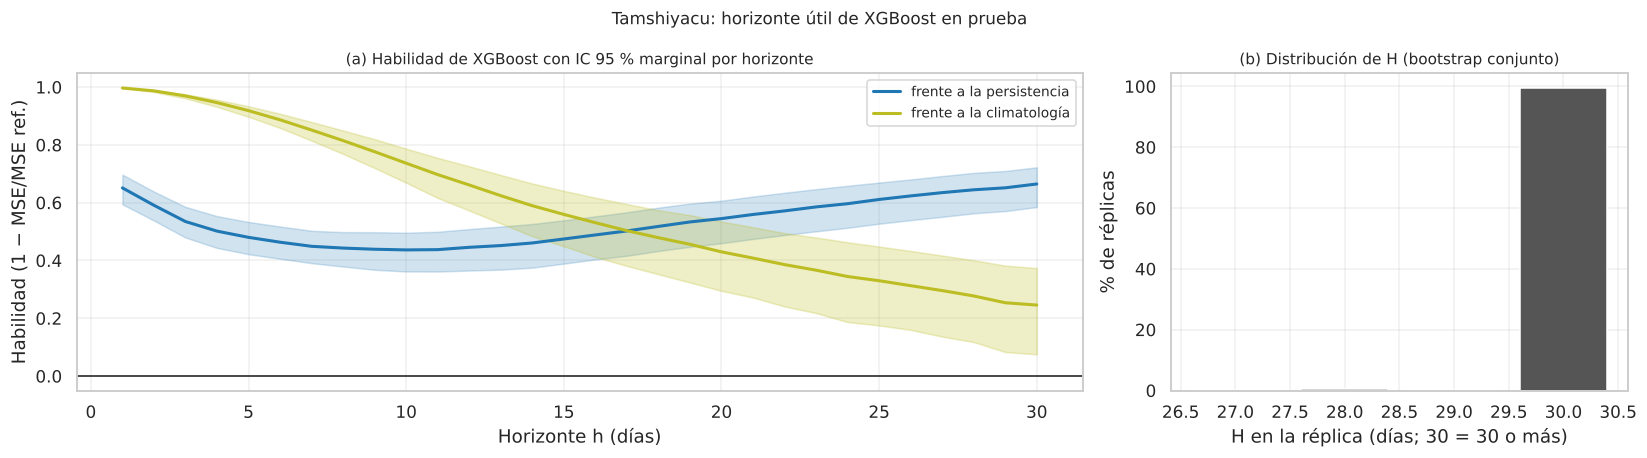

In [15]:
ic, cur = IC[MEJOR], CURVAS[MEJOR]
rep = C.replicas_h(cur)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [2.2, 1]})
ax[0].plot(hh, TAB[MEJOR]['hab_pers'], color='#1f77b4', lw=2, label='frente a la persistencia')
ax[0].fill_between(hh, ic['pers_inf'], ic['pers_sup'], color='#1f77b4', alpha=0.2)
ax[0].plot(hh, TAB[MEJOR]['hab_clim'], color='#bcbd22', lw=2, label='frente a la climatología')
ax[0].fill_between(hh, ic['clim_inf'], ic['clim_sup'], color='#bcbd22', alpha=0.25)
ax[0].axhline(0, color='k', lw=1)
hc, hp = int(hu_tab.loc[MEJOR, 'H cota 95 % (d)']), int(hu_tab.loc[MEJOR, 'H puntual (d)'])
for v, col, et, y in [(hc, 'crimson', f'H cota 95 % = {hc} d', 0.92), (hp, '#555', f'H puntual = {hp} d', 0.80)]:
    if 0 < v < 30:
        ax[0].axvline(v + 0.5, color=col, ls='--', lw=1.2)
        ax[0].text(v + 0.7, y, et, color=col, fontsize=9, transform=ax[0].get_xaxis_transform())
ax[0].set_xlabel('Horizonte h (días)'); ax[0].set_ylabel('Habilidad (1 − MSE/MSE ref.)'); ax[0].legend(fontsize=9); ax[0].grid(True, alpha=0.3)
ax[0].set_title(f'(a) Habilidad de {MEJOR} con IC 95 % marginal por horizonte', fontsize=10)
vals, cnt = np.unique(rep, return_counts=True)
ax[1].bar(vals, cnt / len(rep) * 100, color='#555', width=0.8)
ax[1].set_xlabel('H en la réplica (días; 30 = 30 o más)'); ax[1].set_ylabel('% de réplicas'); ax[1].grid(True, alpha=0.3)
ax[1].set_title('(b) Distribución de H (bootstrap conjunto)', fontsize=10)
fig.suptitle(f'{ESTACION}: horizonte útil de {MEJOR} en prueba', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig03_habilidad_ic.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:** **(a)** las habilidades de XGBoost frente a la persistencia y a la climatología son positivas en los 30 días y sus IC 95 % marginales no tocan el cero (a 30 días, frente a la climatología, de 0.08 a 0.37). **(b)** Casi todas las réplicas tienen H = 30.

---
## 7. Evaluación en las fechas comunes de las dos estaciones
Métricas, horizonte útil y caudales altos se recalculan sobre la **intersección explícita** de las fechas de emisión válidas de prueba de Racarumi y Tamshiyacu (cada emisión con sus 30 objetivos observados, así que también coinciden los pares emisión–horizonte).
**Por qué:** un mismo límite de fecha no garantiza las mismas emisiones: los vacíos de cada estación son distintos. Esta es la base de la comparación entre estaciones (cuaderno 03). No se exige que ambos ríos tengan crecidas en las mismas fechas: se informa cuántos días altos tiene cada uno.

In [16]:
FC = C.fechas_comunes()
sel_c = np.where(fechas_p.isin(FC))[0]
assert len(sel_c) == len(FC), 'todas las fechas comunes deben ser emisiones válidas de esta estación'
print(f'Fechas comunes: {len(sel_c):,} de {len(fechas_p):,} emisiones de prueba de {ESTACION} '
      f'({FC.min():%Y-%m-%d} a {FC.max():%Y-%m-%d})')
TAB_C, filas_c, CURVAS_C = {}, [], {}
OBS_C, PERS_C, CLIM_C = OBS[sel_c], PERS[sel_c], CLIM[sel_c]
for n in TODOS:
    TAB_C[n] = C.tabla_metricas(OBS_C, PRED[n][sel_c], PERS_C, CLIM_C)
    CURVAS_C[n] = C.bootstrap_curvas(fechas_p[sel_c], OBS_C, PRED[n][sel_c], PERS_C, CLIM_C, B=B)
    filas_c.append({'modelo': n, **C.fila_h(C.horizontes(TAB_C[n], CURVAS_C[n])),
                    **{f'NSE h={h}': TAB_C[n].loc[h, 'NSE'] for h in (1, 3, 7, 15, 30)}})
pd.concat(TAB_C, names=['modelo', 'h']).reset_index().to_csv(RUTA_TAB / 'tabla_metricas_prueba_comun.csv', index=False)
ref_c = pd.DataFrame({'NSE persistencia': [C.nse(OBS_C[:, j], PERS_C[:, j]) for j in range(H)],
                      'NSE climatología': [C.nse(OBS_C[:, j], CLIM_C[:, j]) for j in range(H)]}, index=pd.Index(C.HORIZONTES, name='h'))
ref_c.to_csv(RUTA_TAB / 'tabla_referencias_prueba_comun.csv')
hu_c = pd.DataFrame(filas_c).set_index('modelo')
hu_c.to_csv(RUTA_TAB / 'tabla_horizonte_util_comun.csv')
CREC_C = {n: C.metricas_crecida(OBS_C, PRED[n][sel_c], P95) for n in TODOS}
CREC_C['Persistencia'] = C.metricas_crecida(OBS_C, PERS_C, P95)
pd.concat(CREC_C, names=['modelo', 'h']).reset_index().to_csv(RUTA_TAB / 'tabla_crecidas_prueba_comun.csv', index=False)
print(f"Días altos (Q(t+1) > P95) en fechas comunes: {int(CREC_C['Persistencia'].loc[1, 'n_altos'])}")
hu_c.round(3)

Fechas comunes: 2,373 de 3,252 emisiones de prueba de Tamshiyacu (2016-01-01 a 2023-03-31)


Días altos (Q(t+1) > P95) en fechas comunes: 29


,H puntual (d),H cota 95 % (d),H p05 (d),H mediana (d),H p95 (d),P(H ≥ 30),H marginal estricto (d),NSE ≥ 0.5 hasta (d),NSE h=1,NSE h=3,NSE h=7,NSE h=15,NSE h=30
modelo,,,,,,,,,,,,,
Regresión lineal,22,17,17,22,30,0.057,16,30,0.999,0.993,0.963,0.879,0.770
Random Forest,27,21,21,27,30,0.293,20,30,0.999,0.993,0.967,0.893,0.804
XGBoost,30,22,22,30,30,0.594,21,30,0.999,0.993,0.967,0.894,0.820
KNN,27,20,20,28,30,0.392,19,30,0.999,0.993,0.967,0.891,0.809
MLP,27,21,21,28,30,0.355,20,30,0.999,0.993,0.966,0.892,0.809
LSTM,30,27,27,30,30,0.891,25,30,0.999,0.991,0.964,0.900,0.834
Combinado por horizonte,30,22,22,30,30,0.594,21,30,0.999,0.993,0.967,0.894,0.820


**Interpretación:** en las 2 373 fechas comunes (73 % de la prueba de Tamshiyacu: se pierden 2023-04 a 2025) el horizonte se acorta: **H cota 95 % de 22 días con XGBoost** (estimación puntual ≥ 30; P(H ≥ 30) = 0.59), 27 con la LSTM, 20–21 con Random Forest, KNN y MLP, y 17 con la regresión lineal. Solo hay 29 días altos. Este subconjunto es la base de la comparación entre estaciones (cuaderno 03).

---
## 8. Desempeño durante caudales elevados
Los días de prueba en que el caudal observado en t + h supera el P95 de entrenamiento se comparan con los ordinarios, por horizonte: error absoluto (MAE, RMSE en m³/s), error relativo mediano, sesgo (PBIAS) en días altos frente a ordinarios, y una tabla de contingencia **diaria** de días sobre el P95 (POD, FAR y CSI con las mismas unidades: días).
**Por qué:** un error porcentual pequeño en un río grande puede ser un error absoluto grande. La detección diaria **no distingue** entre anticipar un evento nuevo y pronosticar que uno ya iniciado continuará; eso se evalúa en el cuaderno 04.

In [17]:
CREC = {n: C.metricas_crecida(OBS, PRED[n], P95) for n in TODOS}
CREC['Persistencia'] = C.metricas_crecida(OBS, PERS, P95)
crec = pd.concat(CREC, names=['modelo', 'h']).reset_index()
crec.to_csv(RUTA_TAB / 'tabla_crecidas_prueba.csv', index=False)
print(f"Días de prueba con Q(t+1) > P95: {int(CREC['Persistencia'].loc[1, 'n_altos'])} de {len(OBS)}")
crec[crec['h'].isin([1, 3, 7, 15]) & crec['modelo'].isin([MEJOR, 'Persistencia'])].set_index(['modelo', 'h'])[
    ['n_altos', 'MAE_altos', 'MAE_ordinarios', 'error_rel_altos', 'error_rel_ordinarios', 'PBIAS_altos', 'POD', 'FAR', 'CSI']].round(3)

Días de prueba con Q(t+1) > P95: 77 de 3252


n_altos  MAE_altos  MAE_ordinarios  error_rel_altos  \
modelo       h                                                         
XGBoost      1        77    126.313         194.153            0.175   
             3        77    315.004         659.110            0.404   
             7        77    506.129        1514.592            0.781   
             15       77    783.318        2676.659            1.010   
Persistencia 1        77    133.163         365.517            0.219   
             3        77    309.596        1014.491            0.520   
             7        77    631.632        2093.678            1.136   
             15       77   1451.705        3817.109            2.542   

                 error_rel_ordinarios  PBIAS_altos    POD    FAR    CSI  
modelo       h                                                           
XGBoost      1                  0.465       -0.025  0.961  0.013  0.949  
             3                  1.686       -0.162  0.935  0.077  0.867  
             7                  4.060       -0.373  0.870  0.162  0.744  
             15                 7.416       -0.146  0.831  0.396  0.538  
Persistencia 1                  0.972       -0.023  0.961  0.039  0.925  
             3                  2.706       -0.138  0.883  0.117  0.791  
             7                  5.697       -0.580  0.727  0.273  0.571  
             15                11.527       -2.153  0.519  0.481  0.351

**Interpretación (XGBoost frente a persistencia, 77 días altos):**
- **En términos relativos los días altos se pronostican mejor que los ordinarios:** error mediano de 0.18 % frente a 0.46 % a 1 día, 0.78 % frente a 4.1 % a 7 días y 1.0 % frente a 7.4 % a 15 días.
- **En términos absolutos el error no es pequeño:** MAE en días altos de 126 m³/s a 1 día, 506 a 7 días, 783 a 15 días y 2 295 a 30 días; menor que en días ordinarios (194, 1 515, 2 677 y 3 548 m³/s) porque el pico del Amazonas es una meseta lenta.
- **Sesgo pequeño:** PBIAS en días altos entre −0.03 % y −0.4 % hasta 15 días; −2.6 % a 30 días.
- **Frente a la persistencia:** similar a 1–3 días en días altos (126 frente a 133 m³/s a 1 día) y mejor desde los 7 días (506 frente a 632 m³/s).
- **Detección diaria del P95:** CSI 0.95 a 1 día, 0.87 a 3 días, 0.74 a 7 días y 0.54 a 15 días (persistencia 0.92, 0.79, 0.57 y 0.35). Incluye días dentro de eventos ya iniciados. Con 3 eventos, estas cifras son indicativas.

### 8.1 Errores por evento
Cada evento de la prueba (descripción retrospectiva: días sobre el P95; tramos separados por menos de 7 días observados bajo el umbral se unen) se describe con el mejor modelo y h = 1, 3 y 7:
- **error firmado en el pico** = pronóstico para el día del pico − pico observado (negativo = subestimación);
- **máximo pronosticado** con esa anticipación en la ventana del evento extendida h + 3 días después de su fin (para no truncar retrasos de hasta h días) y su **desfase** respecto al día del pico (positivo = tarde).
Se informa la distribución de los desfases, no solo su mediana.

In [18]:
EV = C.eventos(q, P95, '2016-01-01')
pos_p = {f: i for i, f in enumerate(fechas_p)}
filas_e = []
for r in EV.itertuples():
    for h in (1, 3, 7):
        i = pos_p.get(r.fecha_pico - pd.Timedelta(days=h))
        pron_pico = PRED[MEJOR][i, h - 1] if i is not None else np.nan
        dias_ev = pd.date_range(r.inicio - pd.Timedelta(days=3), r.fin + pd.Timedelta(days=h + 3))
        vals = [(d, PRED[MEJOR][pos_p[d - pd.Timedelta(days=h)], h - 1]) for d in dias_ev if (d - pd.Timedelta(days=h)) in pos_p]
        dmax, vmax = max(vals, key=lambda x: x[1]) if vals else (pd.NaT, np.nan)
        filas_e.append({'inicio': r.inicio.date(), 'pico obs (m³/s)': r.pico, 'h': h, 'pronóstico para el pico': pron_pico,
                        'error firmado en el pico (m³/s)': pron_pico - r.pico,
                        'error relativo firmado en el pico (%)': 100 * (pron_pico - r.pico) / r.pico,
                        'máximo pronosticado': vmax, 'error relativo firmado del máximo (%)': 100 * (vmax - r.pico) / r.pico,
                        'desfase del máximo (d)': (dmax - r.fecha_pico).days if vals else np.nan})
ev_tab = pd.DataFrame(filas_e)
ev_tab.to_csv(RUTA_TAB / 'tabla_eventos_pronostico.csv', index=False)
print(f'Eventos en prueba: {len(EV)} | modelo: {MEJOR}')
g = ev_tab.groupby('h')
res_ev = pd.DataFrame({
    'eventos con pronóstico': g['pronóstico para el pico'].count(),
    'error firmado mediano (m³/s)': g['error firmado en el pico (m³/s)'].median(),
    'error relativo firmado mediano (%)': g['error relativo firmado en el pico (%)'].median(),
    'eventos subestimados en el pico': g['error firmado en el pico (m³/s)'].apply(lambda s: int((s < 0).sum())),
    'error relativo mediano del máximo (%)': g['error relativo firmado del máximo (%)'].median(),
    'desfase p25 (d)': g['desfase del máximo (d)'].quantile(0.25), 'desfase mediano (d)': g['desfase del máximo (d)'].median(),
    'desfase p75 (d)': g['desfase del máximo (d)'].quantile(0.75),
    'eventos con desfase = h': pd.Series({h: int((ev_tab.loc[ev_tab['h'] == h, 'desfase del máximo (d)'] == h).sum()) for h in (1, 3, 7)})})
res_ev.to_csv(RUTA_TAB / 'tabla_eventos_resumen.csv')
res_ev.round(2)

Eventos en prueba: 3 | modelo: XGBoost


,eventos con pronóstico,error firmado mediano (m³/s),error relativo firmado mediano (%),eventos subestimados en el pico,error relativo mediano del máximo (%),desfase p25 (d),desfase mediano (d),desfase p75 (d),eventos con desfase = h
1,3,-219.27,-0.45,2,0.29,0.5,1.0,1.0,2
3,3,-189.33,-0.39,3,0.43,2.5,3.0,3.0,2
7,3,-110.70,-0.23,2,0.59,6.5,7.0,7.0,2


**Interpretación — solo 3 eventos en la prueba (2019, 2022 y 2025):**
- **Error firmado en el día del pico (XGBoost):** mediana de −219 m³/s (−0.4 %) a 1 día, −189 m³/s (−0.4 %) a 3 días y −111 m³/s (−0.2 %) a 7 días; subestimados 2, 3 y 2 de los 3 eventos.
- **Máximo pronosticado:** entre +0.2 % y +5 % del pico (mediana +0.3 % a 1 día, +0.4 % a 3 días y +0.6 % a 7 días).
- **Desfase del máximo:** 0–1 día a 1 día, 2–3 días a 3 días y 6–7 días a 7 días. Como el pico es una meseta de 1 a 7 semanas sobre el P95, el día exacto del máximo está mal definido y el desfase no indica un error importante de magnitud.

**Figura 4.** (a) Error relativo mediano en días altos y ordinarios; (b) error absoluto medio (MAE); (c) CSI diario de días sobre el P95; del mejor modelo y de la persistencia.

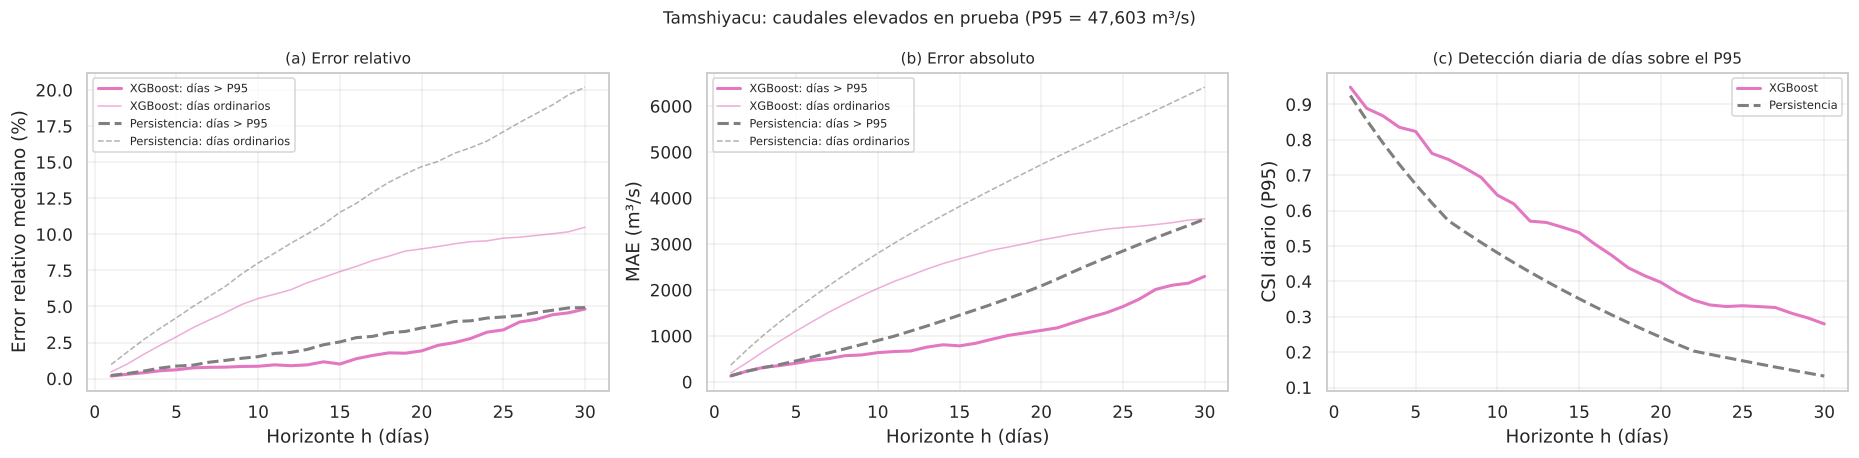

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for n, col, ls in [(MEJOR, COLOR[MEJOR], '-'), ('Persistencia', COLOR['Persistencia'], '--')]:
    t = CREC[n]
    ax[0].plot(hh, t['error_rel_altos'], color=col, ls=ls, lw=2, label=f'{n}: días > P95')
    ax[0].plot(hh, t['error_rel_ordinarios'], color=col, ls=ls, lw=1, alpha=0.6, label=f'{n}: días ordinarios')
    ax[1].plot(hh, t['MAE_altos'], color=col, ls=ls, lw=2, label=f'{n}: días > P95')
    ax[1].plot(hh, t['MAE_ordinarios'], color=col, ls=ls, lw=1, alpha=0.6, label=f'{n}: días ordinarios')
    ax[2].plot(hh, t['CSI'], color=col, ls=ls, lw=2, label=n)
ax[0].set_ylabel('Error relativo mediano (%)'); ax[1].set_ylabel('MAE (m³/s)'); ax[2].set_ylabel('CSI diario (P95)')
for a, ti in zip(ax, ['(a) Error relativo', '(b) Error absoluto', '(c) Detección diaria de días sobre el P95']):
    a.set_xlabel('Horizonte h (días)'); a.set_title(ti, fontsize=10); a.grid(True, alpha=0.3); a.legend(fontsize=7.5)
fig.suptitle(f'{ESTACION}: caudales elevados en prueba (P95 = {P95:,.0f} m³/s)', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig04_crecidas.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:** **(a)** el error relativo en días altos (≤ 1 % hasta 15 días) queda por debajo del de días ordinarios en todos los horizontes. **(b)** En m³/s ambos crecen con el horizonte; a 30 días el error en días altos llega a ≈ 2 300 m³/s. **(c)** El CSI diario cae de 0.95 a 0.54 entre 1 y 15 días, siempre por encima de la persistencia.

**Figura 5.** Las dos mayores crecidas del periodo de prueba: caudal observado y pronósticos del mejor modelo emitidos con 1, 3, 7 y 15 días de anticipación (cada punto se dibuja en la fecha pronosticada).

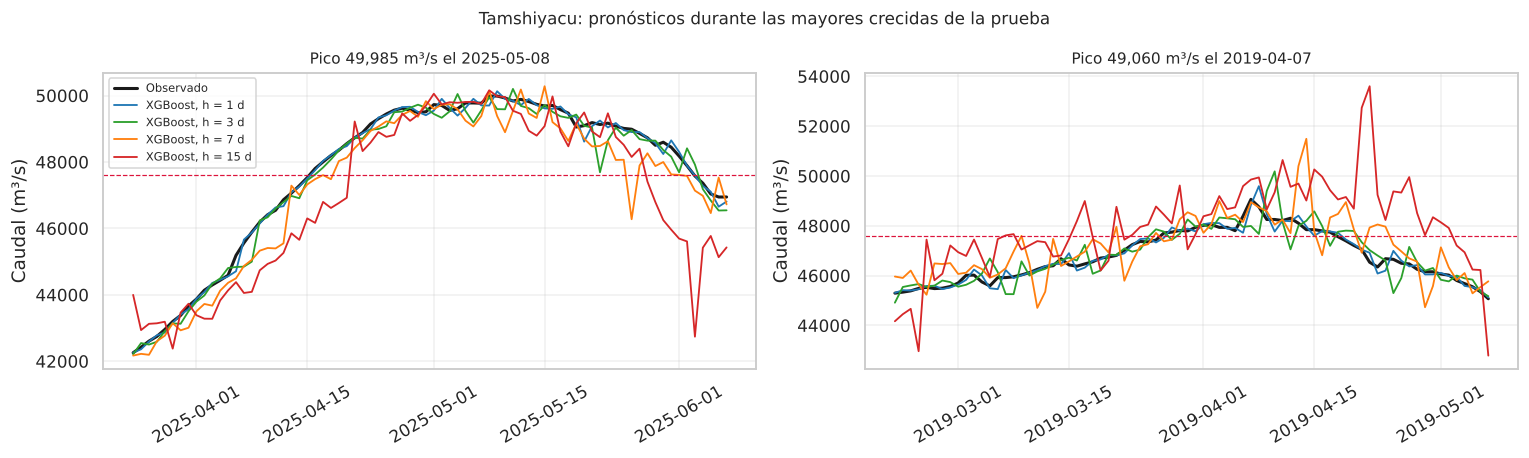

In [20]:
top = EV.sort_values('pico', ascending=False).head(2)
serie_pred = {h: pd.Series(PRED[MEJOR][:, h - 1], index=fechas_p + pd.Timedelta(days=h)) for h in [1, 3, 7, 15]}
fig, ax = plt.subplots(1, len(top), figsize=(14, 4.2), squeeze=False)
for a, (_, e) in zip(ax[0], top.iterrows()):
    v0, v1 = e['fecha_pico'] - pd.Timedelta(days=45), e['fecha_pico'] + pd.Timedelta(days=30)
    a.plot(q.loc[v0:v1].index, q.loc[v0:v1], color='k', lw=2, label='Observado')
    for h, col in zip([1, 3, 7, 15], ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']):
        s = serie_pred[h].loc[v0:v1].asfreq('D')
        a.plot(s.index, s, color=col, lw=1.2, label=f'{MEJOR}, h = {h} d')
    a.axhline(P95, color='crimson', ls='--', lw=0.8)
    a.set_title(f"Pico {e['pico']:,.0f} m³/s el {e['fecha_pico']:%Y-%m-%d}", fontsize=10)
    a.set_ylabel('Caudal (m³/s)'); a.grid(True, alpha=0.3); a.tick_params(axis='x', rotation=30)
ax[0][0].legend(fontsize=7.5)
fig.suptitle(f'{ESTACION}: pronósticos durante las mayores crecidas de la prueba', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig05_eventos.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:** en las dos mayores crecidas de la prueba (49 985 m³/s el 2025-05-08 y 49 060 m³/s el 2019-04-07) los pronósticos a 1, 3 y 7 días siguen la meseta del pico; el error en el día del pico va de −2.2 % a +0.3 % (a 1 día: 49 699 y 48 841 m³/s).

---
## 9. Sensibilidad a la longitud de la historia y al calendario
**XGBoost** (hiperparámetros de la sección 4, una semilla) se reentrena cambiando los días de historia: L = 1, 3, 7, 15, 30 y 60 (con L = 1 solo conoce el caudal de hoy y la fecha), y una variante **L = 30 sin calendario**. Todas usan el mismo conjunto de muestras (el de L = 60) y su propia corrección de retransformación. XGBoost se usa para todos los análisis auxiliares de las dos estaciones (no se elige el modelo según el resultado).
**Cómo leerlo:** mide cuánta **información predictiva** aportan los días antecedentes y el calendario en este experimento. No mide la memoria física de la cuenca.

In [21]:
BASE_MEM = C.BASE_AUX
m60 = C.construir_muestras(q, L=60, H=H, esc=esc, eps=EPS)
p60 = C.particion(m60)
it60, ip60 = np.concatenate([p60['ent'], p60['val']]), p60['pru']
obs60, pers60, clim60 = m60.q_obs[ip60], C.pred_persistencia(m60, ip60), C.pred_climatologia(m60, ip60, C.climatologia(q, hasta=C.FIN_VALIDACION))
mem = {}
for etiqueta, Lm, cal in [('1', 1, True), ('3', 3, True), ('7', 7, True), ('15', 15, True), ('30', 30, True), ('60', 60, True),
                          ('30 sin calendario', 30, False)]:
    sub = C.Muestras(fechas=m60.fechas, ventana=m60.ventana[:, -Lm:], doy=m60.doy, zt=m60.zt, y=m60.y,
                     q_obs=m60.q_obs, q_t=m60.q_t, eps=m60.eps, L=Lm)
    Xm, _ = C.matriz_tabular(sub, calendario=cal)
    mod = C.crear_tabular(BASE_MEM, mejores[BASE_MEM]).fit(Xm[p60['ent']], sub.y[p60['ent']])
    fac = np.mean(np.exp(sub.y[p60['val']] - mod.predict(Xm[p60['val']])), axis=0)
    mod = C.crear_tabular(BASE_MEM, mejores[BASE_MEM]).fit(Xm[it60], sub.y[it60])
    mem[etiqueta] = C.tabla_metricas(obs60, C.a_caudal(sub, mod.predict(Xm[ip60]), ip60, fac), pers60, clim60)
memoria = pd.concat(mem, names=['L', 'h']).reset_index()
memoria.to_csv(RUTA_TAB / 'tabla_memoria.csv', index=False)
print(f'Modelo usado: {BASE_MEM} | muestras de prueba comunes: {len(ip60)}')
memoria[memoria['h'].isin([1, 3, 7, 15, 30])].pivot(index='L', columns='h', values='hab_pers').reindex(list(mem)).round(3).add_prefix('hab. pers. h=')

Modelo usado: XGBoost | muestras de prueba comunes: 3222


h,hab. pers. h=1,hab. pers. h=3,hab. pers. h=7,hab. pers. h=15,hab. pers. h=30
L,,,,,
1,0.148,0.193,0.278,0.447,0.644
3,0.647,0.543,0.458,0.485,0.653
7,0.648,0.538,0.456,0.481,0.653
15,0.649,0.532,0.448,0.479,0.653
30,0.647,0.533,0.443,0.468,0.656
60,0.648,0.532,0.449,0.462,0.649
30 sin calendario,0.643,0.498,0.372,0.307,0.378


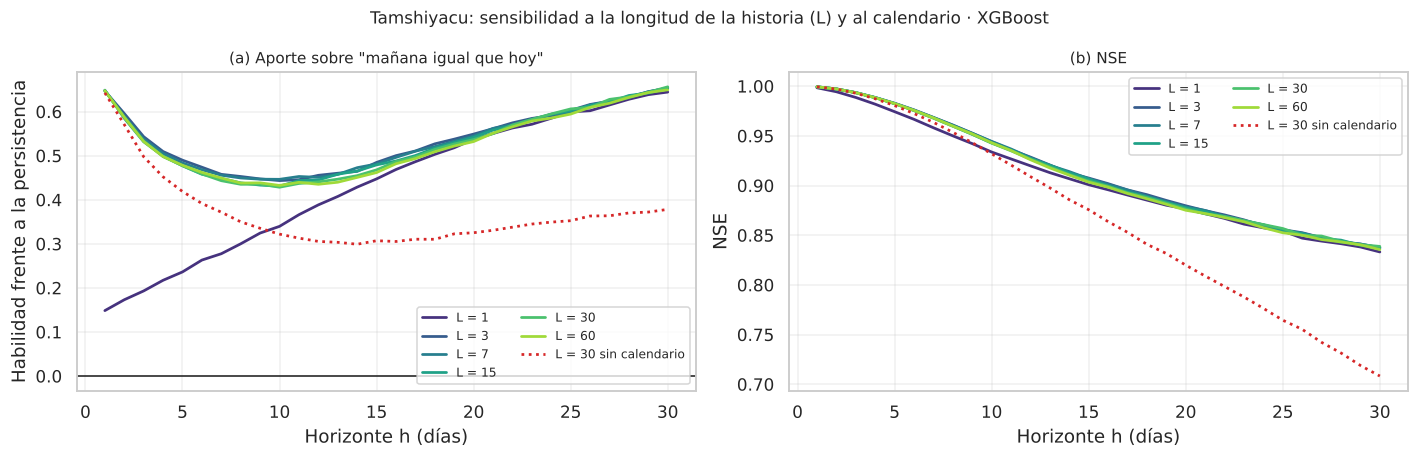

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
pal = sns.color_palette('viridis', 6)
for (et, t), col in zip(mem.items(), list(pal) + ['#d62728']):
    ls = ':' if 'sin' in et else '-'
    ax[0].plot(hh, t['hab_pers'], color=col, lw=1.8, ls=ls, label=f'L = {et}')
    ax[1].plot(hh, t['NSE'], color=col, lw=1.8, ls=ls, label=f'L = {et}')
ax[0].axhline(0, color='k', lw=1)
ax[0].set_ylabel('Habilidad frente a la persistencia'); ax[1].set_ylabel('NSE')
for a, ti in zip(ax, ['(a) Aporte sobre "mañana igual que hoy"', '(b) NSE']):
    a.set_xlabel('Horizonte h (días)'); a.set_title(ti, fontsize=10); a.grid(True, alpha=0.3); a.legend(fontsize=8, ncol=2)
fig.suptitle(f'{ESTACION}: sensibilidad a la longitud de la historia (L) y al calendario · {BASE_MEM}', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig06_memoria.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación — lo que informa es la tendencia reciente, más que la historia larga (XGBoost):**
- Con **L = 1** (solo el caudal de hoy y la fecha) la habilidad frente a la persistencia es 0.15 a 1 día y 0.28 a 7 días; con **L = 3** sube a 0.65 y 0.46. Los 2–3 días anteriores aportan la **tendencia**, que en el Amazonas se mantiene por semanas.
- **Más de 3 días** de historia casi no cambia el resultado (≤ 0.03).
- **Sin calendario** (L = 30) la habilidad baja a 0.37 a 7 días, 0.31 a 15 días y 0.38 a 30 días, y el NSE a 30 días de 0.84 a 0.71.
- **Cómo leerlo:** mide la información predictiva de los caudales antecedentes en este experimento, no la memoria física de la cuenca.

---
## 10. Variables más usadas por el modelo
**Importancia por permutación de grupos:** en el XGBoost final (semilla 42) se permutan juntas las columnas de cada grupo en la prueba y se mide cuánto aumenta el error (MSE en m³/s) en h = 1, 3, 7, 15 y 30. Mide cuánto **usa** el modelo cada grupo; con variables correlacionadas no demuestra causalidad.

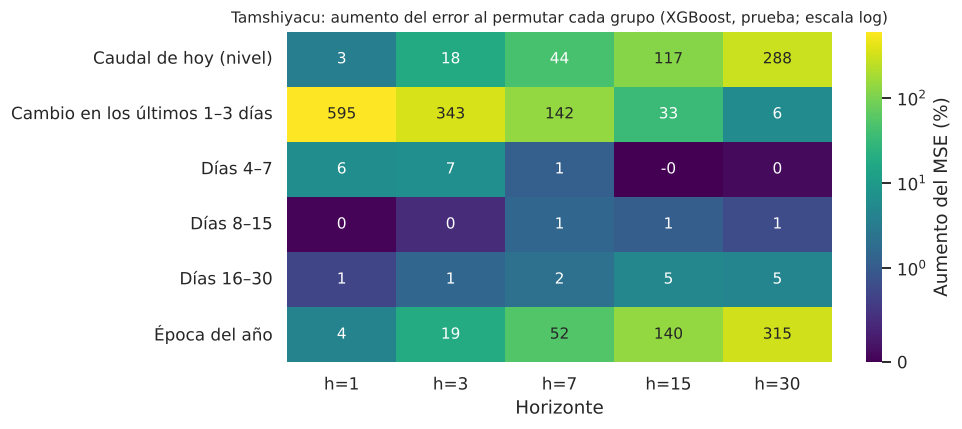

,h=1,h=3,h=7,h=15,h=30
grupo,,,,,
Caudal de hoy (nivel),3.4,17.6,44.5,116.6,288.2
Cambio en los últimos 1–3 días,594.8,342.9,141.7,33.3,5.5
Días 4–7,6.3,6.5,1.1,-0.1,0.1
Días 8–15,0.0,0.4,1.5,1.1,0.8
Días 16–30,0.7,1.4,2.1,4.8,4.5
Época del año,4.2,18.5,51.8,139.8,315.1


In [23]:
imp = C.importancia_grupos(MODELO_AUX, X[idx_p], OBS, m, idx_p, C.grupos_variables(nombres), [1, 3, 7, 15, 30], FACTOR[C.BASE_AUX])
imp.to_csv(RUTA_TAB / 'tabla_importancia.csv')
from matplotlib.colors import SymLogNorm
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(imp * 100, annot=True, fmt='.0f', cmap='viridis', ax=ax, cbar_kws={'label': 'Aumento del MSE (%)'},
            norm=SymLogNorm(linthresh=1, vmin=0, vmax=max(float((imp * 100).max().max()), 10)))
ax.set_xlabel('Horizonte'); ax.set_ylabel('')
ax.set_title(f'{ESTACION}: aumento del error al permutar cada grupo ({C.BASE_AUX}, prueba; escala log)', fontsize=10)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig07_importancia.png', dpi=200, bbox_inches='tight'); plt.show()
(imp * 100).round(1)

**Interpretación (XGBoost):**
- **La tendencia de los últimos 1–3 días es lo más usado hasta los 7 días:** sin ella el error aumenta 595 % a 1 día, 343 % a 3 días y 142 % a 7 días.
- **Después pesan el nivel de hoy y la época del año** (+117 % y +140 % a 15 días; +288 % y +315 % a 30 días).
- **La historia de 4 a 30 días aporta ≤ 7 %.** Describe el uso del modelo, no causas.

---
## 11. Estabilidad temporal: validación con varios orígenes y selección interna
El protocolo completo se repite con cuatro orígenes temporales. Para cada uno, **todo** se decide con el pasado del origen: ε, umbral de escalones, P95, climatologías, mallas de hiperparámetros (validación interna de 7 años, con calibración en sus 3 primeros años y selección en los 4 últimos, igual que el protocolo principal), épocas de la LSTM (bloque de parada interno), semillas y corrección de retransformación.

| Prueba | Entrenamiento interno | Validación interna |
|---|---|---|
| 1995–2001 | inicio–1987 | 1988–1994 |
| 2002–2008 | inicio–1994 | 1995–2001 |
| 2009–2015 | inicio–2001 | 2002–2008 |
| 2016–fin | inicio–2008 | 2009–2015 (es el protocolo principal: se reutilizan sus resultados) |

Se evalúan la regresión lineal, XGBoost, la LSTM y el modelo seleccionado en la sección 5 (si es otro). Un origen se omite si su entrenamiento interno tiene menos de 1 000 muestras o su validación interna no permite los dos bloques.

In [24]:
CORTES = [('1995–2001', '1987-12-31', '1994-12-31', '2001-12-31'), ('2002–2008', '1994-12-31', '2001-12-31', '2008-12-31'),
          ('2009–2015', '2001-12-31', '2008-12-31', '2015-12-31')]
modelos_est = list(dict.fromkeys(['Regresión lineal', C.BASE_AUX, 'LSTM', MEJOR]))
filas_f, curvas_f = [], {}

def fila_origen(nombre_c, n, t, hz, info_c, params):
    return {'prueba': nombre_c, 'modelo': n, **info_c, 'parámetros elegidos': json.dumps(params), **C.fila_h(hz),
            **{f'NSE h={h}': t.loc[h, 'NSE'] for h in (1, 7, 15, 30)}}

for nombre_c, fe_c, fv_c, fp_c in CORTES:
    eps_c, esc_c = C.eps_entrenamiento(q, fe_c), C.escalones(q, fe_c)
    mc = C.construir_muestras(q, L=L, H=H, esc=esc_c, eps=eps_c)
    pc = C.particion(mc, fe_c, fv_c, fp_c)
    if len(pc['ent']) < 1000 or len(pc['val']) < 300 or len(pc['pru']) < 300:
        print(f"{nombre_c}: se omite (entrenamiento {len(pc['ent'])}, validación {len(pc['val'])}, prueba {len(pc['pru'])} muestras)"); continue
    P95_c = float(np.nanpercentile(q.loc[:fe_c], 95))
    Xc, _ = C.matriz_tabular(mc)
    ec, vc, tc = pc['ent'], pc['val'], pc['pru']
    itc = np.concatenate([ec, vc])
    o, pe = mc.q_obs[tc], C.pred_persistencia(mc, tc)
    pcl = C.pred_climatologia(mc, tc, C.climatologia(q, hasta=fv_c))
    try:
        VCc = C.ValidacionCausal(mc, vc, fe_c)
    except ValueError as err:
        print(f'{nombre_c}: se omite ({err})'); continue
    ov, aq = VCc.obs_sel, VCc.a_q
    info_c = {'muestras ent.': len(ec), 'muestras val.': len(vc), 'muestras prueba': len(tc), 'escalones': len(esc_c),
              'días altos prueba (P95 propio)': int((o[:, 0] > P95_c).sum()),
              'NSE pers. h=7': C.nse(o[:, 6], pe[:, 6]), 'NSE clim. h=7': C.nse(o[:, 6], pcl[:, 6])}
    fin_par_c = str((pd.Timestamp(fe_c) - pd.DateOffset(years=4)).date())
    ec_in = ec[mc.fechas[ec] + pd.Timedelta(days=H) <= pd.Timestamp(fin_par_c)]
    ec_par = ec[mc.fechas[ec] > pd.Timestamp(fin_par_c)]
    for n in modelos_est:
        t0 = time.time()
        semillas = C.SEMILLAS if n in C.ESTOCASTICOS else [C.SEMILLA]
        if n == 'LSTM':
            mejor_p, mejor_v = None, -np.inf
            for params in C.combinaciones(C.MALLAS['LSTM']):
                v = C.nse_medio(aq(C.LSTMProtocolo(mc, ec_in, ec_par, **params).ajustar(ec).predecir(vc)), ov)
                if v > mejor_v:
                    mejor_p, mejor_v = params, v
            yv_s, yp_s = [], []
            for s in semillas:
                lp = C.LSTMProtocolo(mc, ec_in, ec_par, semilla=s, **mejor_p).ajustar(ec)
                yv_s.append(lp.predecir(vc)); yp_s.append(lp.reajustar(itc).predecir(tc))
        else:
            sub = C.ajustar_malla(n, Xc[ec], mc.y[ec], Xc[vc], aq, ov)
            mejor_p = json.loads(max(sub, key=lambda f: f['NSE_val'])['parametros'])
            yv_s = [C.crear_tabular(n, mejor_p, s).fit(Xc[ec], mc.y[ec]).predict(Xc[vc]) for s in semillas]
            yp_s = [C.crear_tabular(n, mejor_p, s).fit(Xc[itc], mc.y[itc]).predict(Xc[tc]) for s in semillas]
        fac = C.factor_duan(mc.y[vc], np.mean(yv_s, 0))
        pr = C.a_caudal(mc, np.mean(yp_s, 0), tc, fac)
        t = C.tabla_metricas(o, pr, pe, pcl)
        hz = C.horizontes(t, C.bootstrap_curvas(mc.fechas[tc], o, pr, pe, pcl, B=min(B, 500)))
        curvas_f[(nombre_c, n)] = t
        filas_f.append(fila_origen(nombre_c, n, t, hz, info_c, mejor_p))
        print(f"{nombre_c} {n:22s} H cota {hz['H_cota']:2d} | H puntual {hz['H_puntual']:2d} | {time.time() - t0:5.0f} s | {mejor_p}")
# origen 2016–fin = protocolo principal (mismas reglas, ya calculado)
info_p = {'muestras ent.': len(ie), 'muestras val.': len(iv), 'muestras prueba': len(idx_p), 'escalones': len(esc),
          'días altos prueba (P95 propio)': int((OBS[:, 0] > P95).sum()),
          'NSE pers. h=7': ref.loc[7, 'NSE persistencia'], 'NSE clim. h=7': ref.loc[7, 'NSE climatología']}
for n in modelos_est:
    curvas_f[('2016–fin', n)] = TAB[n]
    filas_f.append(fila_origen('2016–fin', n, TAB[n], C.horizontes(TAB[n], CURVAS[n]), info_p, mejores[n]))
estab = pd.DataFrame(filas_f)
estab.to_csv(RUTA_TAB / 'tabla_estabilidad_temporal.csv', index=False)
estab.drop(columns=['parámetros elegidos']).round(3)

1995–2001: se omite (entrenamiento 863, validación 1908, prueba 1849 muestras)
2002–2008 Regresión lineal       H cota 21 | H puntual 30 |     0 s | {}


2002–2008 XGBoost                H cota 30 | H puntual 30 |   163 s | {'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 1.0, 'n_estimators': 100}


2002–2008 LSTM                   H cota 30 | H puntual 30 |    27 s | {'oculto': 64, 'dropout': 0.2}
2009–2015 Regresión lineal       H cota 26 | H puntual 30 |     0 s | {}


2009–2015 XGBoost                H cota 30 | H puntual 30 |   178 s | {'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 1.0, 'n_estimators': 100}


2009–2015 LSTM                   H cota 30 | H puntual 30 |    35 s | {'oculto': 32, 'dropout': 0.2}


,prueba,modelo,muestras ent.,muestras val.,muestras prueba,escalones,días altos prueba (P95 propio),NSE pers. h=7,NSE clim. h=7,H puntual (d),...,H p05 (d),H mediana (d),H p95 (d),P(H ≥ 30),H marginal estricto (d),NSE ≥ 0.5 hasta (d),NSE h=1,NSE h=7,NSE h=15,NSE h=30
0,2002–2008,Regresión lineal,2830,1849,2077,44,0,0.925,0.706,30,...,21,30,30,0.566,20,30,0.999,0.955,0.851,0.717
1,2002–2008,XGBoost,2830,1849,2077,44,0,0.925,0.706,30,...,30,30,30,0.958,28,30,0.999,0.961,0.874,0.767
2,2002–2008,LSTM,2830,1849,2077,44,0,0.925,0.706,30,...,30,30,30,0.998,30,30,0.998,0.950,0.874,0.783
3,2009–2015,Regresión lineal,4797,2077,2025,41,219,0.953,0.796,30,...,26,30,30,0.878,25,30,1.000,0.972,0.914,0.826
4,2009–2015,XGBoost,4797,2077,2025,41,219,0.953,0.796,30,...,30,30,30,0.996,30,30,1.000,0.977,0.936,0.874
5,2009–2015,LSTM,4797,2077,2025,41,219,0.953,0.796,30,...,30,30,30,1.000,30,30,0.999,0.972,0.932,0.876
6,2016–fin,Regresión lineal,6904,2025,3252,41,77,0.942,0.785,26,...,21,26,30,0.203,21,30,0.999,0.963,0.882,0.770
7,2016–fin,XGBoost,6904,2025,3252,41,77,0.942,0.785,30,...,30,30,30,0.993,30,30,0.999,0.968,0.906,0.843
8,2016–fin,LSTM,6904,2025,3252,41,77,0.942,0.785,30,...,30,30,30,0.999,30,30,0.999,0.965,0.906,0.849


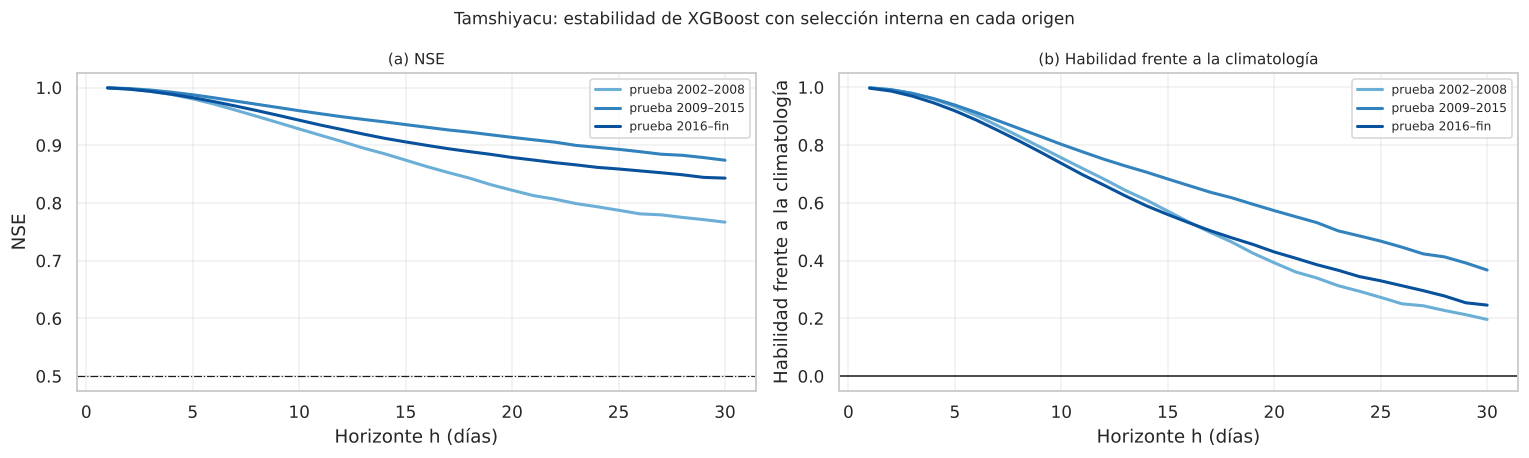

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
orden = ['1995–2001', '2002–2008', '2009–2015', '2016–fin']
pal = dict(zip(orden, ['#9ecae1', '#6baed6', '#3182bd', '#08519c']))
for (nombre_c, n), t in curvas_f.items():
    if n == MEJOR:
        ax[0].plot(hh, t['NSE'], color=pal[nombre_c], lw=2, label=f'prueba {nombre_c}')
        ax[1].plot(hh, t['hab_clim'], color=pal[nombre_c], lw=2, label=f'prueba {nombre_c}')
ax[0].axhline(0.5, color='k', lw=0.8, ls='-.'); ax[1].axhline(0, color='k', lw=1)
ax[0].set_ylabel('NSE'); ax[1].set_ylabel('Habilidad frente a la climatología')
for a, ti in zip(ax, ['(a) NSE', '(b) Habilidad frente a la climatología']):
    a.set_xlabel('Horizonte h (días)'); a.set_title(ti, fontsize=10); a.grid(True, alpha=0.3); a.legend(fontsize=8)
fig.suptitle(f'{ESTACION}: estabilidad de {MEJOR} con selección interna en cada origen', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig08_estabilidad.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación — Tamshiyacu es estable:**
- **XGBoost y la LSTM: H cota 95 % ≥ 30 días** en los tres orígenes evaluables (2002–2008, 2009–2015 y 2016–fin); la regresión lineal, 21, 26 y 21 días.
- **1995–2001 se omite:** con los escalones excluidos, su entrenamiento interno tiene solo 863 muestras.
- En 2002–2008 la prueba no tuvo ningún día sobre su P95 propio: ese origen no informa sobre crecidas.

---
## 12. Sensibilidad a los registros con escalones de nivel
Si la estación tiene escalones, el entrenamiento se repite usando **solo los años sin escalones** (un año se excluye si tiene un escalón) y se evalúa en la misma prueba. Como control, XGBoost se repite **20 veces** con la misma cantidad de años de entrenamiento elegidos al azar **entre los años con escalones** y la misma validación. Para que sean comparables, XGBoost se ajusta con una sola semilla (42) en la referencia con todos los años, en la variante restringida y en los controles.
**Cómo leerlo:** es un análisis de **sensibilidad**, no una prueba de causa. Las variantes difieren a la vez en cantidad de datos, décadas cubiertas y tipos de eventos; por eso se describen los años usados y se ubica la variante restringida dentro de la distribución de los controles. Los hiperparámetros son los de la sección 4.

In [26]:
N_CONTROL = 3 if RAPIDO else 20
if len(esc) == 0:
    sens, sens_resumen = pd.DataFrame(), pd.DataFrame()
    print('Esta estación no tiene escalones de nivel: el análisis no aplica.')
else:
    anios_malos = sorted(set(esc.year))
    permitidos = pd.Series(~q.index.year.isin(anios_malos), index=q.index)
    libres = sorted(set(q.index.year[permitidos & (q.index <= C.FIN_VALIDACION)]))
    print(f'Años con escalón ({len(anios_malos)}): {anios_malos[0]}–{anios_malos[-1]} | años sin escalón hasta 2015: {libres}')
    def variante(perm, n, etiqueta, anios, una_semilla=False):
        ms = C.construir_muestras(q, L=L, H=H, esc=esc, eps=EPS, permitidos=perm)
        ps = C.particion(ms)
        assert (ms.fechas[ps['pru']] == fechas_p).all(), 'la prueba debe ser idéntica'
        Xs, _ = C.matriz_tabular(ms)
        its = np.concatenate([ps['ent'], ps['val']])
        semillas = C.SEMILLAS if (n in C.ESTOCASTICOS and not una_semilla) else [C.SEMILLA]
        if n == 'LSTM':
            e_in = ps['ent'][ms.fechas[ps['ent']] + pd.Timedelta(days=H) <= pd.Timestamp(C.FIN_PARADA)]
            e_par = ps['ent'][ms.fechas[ps['ent']] > pd.Timestamp(C.FIN_PARADA)]
            yv_s, yp_s = [], []
            for s in semillas:
                lp = C.LSTMProtocolo(ms, e_in, e_par, semilla=s, **mejores['LSTM']).ajustar(ps['ent'])
                yv_s.append(lp.predecir(ps['val'])); yp_s.append(lp.reajustar(its).predecir(ps['pru']))
        else:
            yv_s = [C.crear_tabular(n, mejores[n], s).fit(Xs[ps['ent']], ms.y[ps['ent']]).predict(Xs[ps['val']]) for s in semillas]
            yp_s = [C.crear_tabular(n, mejores[n], s).fit(Xs[its], ms.y[its]).predict(Xs[ps['pru']]) for s in semillas]
        fac = np.mean(np.exp(ms.y[ps['val']] - np.mean(yv_s, 0)), axis=0)
        t = C.tabla_metricas(OBS, C.a_caudal(ms, np.mean(yp_s, 0), ps['pru'], fac), PERS, CLIM)
        hz = C.horizontes(t, C.bootstrap_curvas(fechas_p, OBS, C.a_caudal(ms, np.mean(yp_s, 0), ps['pru'], fac), PERS, CLIM, B=min(B, 500)))
        return {'modelo': n, 'entrenamiento': etiqueta, 'años de entrenamiento': anios, 'muestras ent.': len(ps['ent']),
                **C.fila_h(hz), **{f'NSE h={h}': t.loc[h, 'NSE'] for h in (1, 7, 15, 30)}, 'hab. clim. h=30': t.loc[30, 'hab_clim']}
    filas_s = []
    todos_anios = pd.Series(True, index=q.index)
    filas_s.append(variante(todos_anios, C.BASE_AUX, 'todos los años (una semilla)', 'todos', una_semilla=True))
    filas_s.append(variante(permitidos, C.BASE_AUX, 'solo años sin escalones', ', '.join(str(a) for a in libres if a <= 2008), una_semilla=True))
    if MEJOR != C.BASE_AUX:
        hz0 = C.horizontes(TAB[MEJOR], CURVAS[MEJOR])
        filas_s.append({'modelo': MEJOR, 'entrenamiento': 'todos los años (principal)', 'años de entrenamiento': 'todos',
                        'muestras ent.': len(ie), **C.fila_h(hz0), **{f'NSE h={h}': TAB[MEJOR].loc[h, 'NSE'] for h in (1, 7, 15, 30)},
                        'hab. clim. h=30': TAB[MEJOR].loc[30, 'hab_clim']})
        filas_s.append(variante(permitidos, MEJOR, 'solo años sin escalones', ', '.join(str(a) for a in libres if a <= 2008)))
    rng_c = np.random.default_rng(C.SEMILLA)
    n_ent = sum(1 for a in libres if a <= 2008)
    malos_ent = [a for a in anios_malos if a <= 2008]
    val_libre = sorted(set(q.index.year[permitidos & (q.index > C.FIN_ENTRENAMIENTO)]))   # validación y prueba sin escalones (idénticas)
    for r_ in range(N_CONTROL):
        elegidos = sorted(int(a) for a in rng_c.choice(malos_ent, n_ent, replace=False))
        perm_c = pd.Series(q.index.year.isin(elegidos) | q.index.year.isin(val_libre), index=q.index)
        filas_s.append(variante(perm_c, C.BASE_AUX, f'control {r_ + 1}', ', '.join(map(str, elegidos)), una_semilla=True))
    sens = pd.DataFrame(filas_s)
    ctrl = sens[sens['entrenamiento'].str.startswith('control')]
    restr = sens[(sens['modelo'] == C.BASE_AUX) & (sens['entrenamiento'] == 'solo años sin escalones')].iloc[0]
    ref_s = sens[(sens['modelo'] == C.BASE_AUX) & (sens['entrenamiento'] == 'todos los años (una semilla)')].iloc[0]
    cols_r = ['H cota 95 % (d)', 'H puntual (d)', 'NSE h=7', 'NSE h=30', 'muestras ent.']
    sens_resumen = pd.DataFrame({'todos los años': ref_s[cols_r], 'solo años sin escalones': restr[cols_r],
                                 'controles: mínimo': ctrl[cols_r].min(), 'p25': ctrl[cols_r].quantile(0.25),
                                 'mediana': ctrl[cols_r].median(), 'p75': ctrl[cols_r].quantile(0.75), 'máximo': ctrl[cols_r].max(),
                                 'controles ≤ variante restringida (%)': [100 * (ctrl[c_] <= restr[c_]).mean() for c_ in cols_r]})
    sens_resumen.to_csv(RUTA_TAB / 'tabla_sensibilidad_registros_resumen.csv')
sens.to_csv(RUTA_TAB / 'tabla_sensibilidad_registros.csv', index=False)
sens_resumen.round(3) if len(sens_resumen) else sens

Años con escalón (26): 1985–2014 | años sin escalón hasta 2015: [1984, 1996, 2002, 2003, 2007, 2015]


,todos los años,solo años sin escalones,controles: mínimo,p25,mediana,p75,máximo,controles ≤ variante restringida (%)
H cota 95 % (d),30,23,13.000,22.750,24.000,26.250,29.000,35.0
H puntual (d),30,28,25.000,30.000,30.000,30.000,30.000,15.0
NSE h=7,0.967954,0.965537,0.960,0.963,0.964,0.965,0.966,90.0
NSE h=30,0.843116,0.793215,0.749,0.797,0.807,0.813,0.817,20.0
muestras ent.,6904,1310,1235.000,1294.750,1296.000,1354.250,1472.000,65.0


**Interpretación — sensibilidad a los años con escalones (XGBoost, una semilla):**
- **Con todos los años:** H cota ≥ 30 días. **Solo con los 5 años sin escalones hasta 2008** (1984, 1996, 2002, 2003, 2007; 1 310 muestras): **23 días**, y NSE a 30 días de 0.79 frente a 0.84.
- **Controles** (20 repeticiones con 5 años al azar entre los años con escalones, 1 235–1 472 muestras): H cota de 13 a 29 días (mediana 24); el 35 % de los controles queda en 23 días o menos. NSE a 30 días de 0.75 a 0.82 (mediana 0.81).
- **Lectura:** la variante sin escalones se comporta como un entrenamiento de igual tamaño con años que sí tienen escalones. El resultado es compatible con que lo que importa es la **cantidad** de datos, pero no descarta un efecto de **calidad**: las variantes difieren también en las décadas y eventos que cubren.

---
## 13. Síntesis y archivos para la comparación
Archivos que usan los cuadernos siguientes: el resumen (`resumen.json`), los pronósticos de validación y prueba (`predicciones.npz`, que usan los cuadernos 03 y 04 y la página interactiva) y una tabla larga de prueba con estación, modelo, emisión, fecha objetivo, horizonte, observado, pronosticado y calidad de la entrada (`predicciones_prueba_largo.csv.gz`).

In [27]:
resumen_est = dict(
    version=C.VERSION, revision=C.REVISION, rapido=RAPIDO, estacion=ESTACION, cuenca=C.ESTACIONES[ESTACION]['cuenca'], vertiente=C.ESTACIONES[ESTACION]['vertiente'],
    periodo=f"{info['inicio']:%Y-%m-%d} a {info['fin']:%Y-%m-%d}", P95=P95, eps=EPS, mejor_modelo=MEJOR, mayor_nse=MAS_ALTO,
    base_aux=C.BASE_AUX, validacion=VC.resumen(), seleccion=SELEC.reset_index().to_dict(orient='records'),
    mejores_parametros=mejores, epocas_lstm=mejor_lstm.get('epocas'), nse_val=NSE_VAL,
    combinado={str(h): ELEGIDO[h] for h in C.HORIZONTES},
    horizonte=hu_tab.reset_index().to_dict(orient='records'), horizonte_comun=hu_c.reset_index().to_dict(orient='records'),
    fechas_comunes=dict(n=int(len(FC)), inicio=str(FC.min().date()), fin=str(FC.max().date())),
    muestras={k: int(len(v)) for k, v in p.items()}, inventario=m.info, escalones=int(len(esc)), excluidas_escalon=int(m.excluidas_escalon),
    semillas=C.SEMILLAS, minutos=round((time.time() - T_INICIO) / 60, 1))
(RUTA_SAL / 'resumen.json').write_text(json.dumps(resumen_est, ensure_ascii=False, indent=1, default=float), encoding='utf-8')
dias = lambda f: (f - pd.Timestamp('1970-01-01')).days.to_numpy()
np.savez_compressed(RUTA_SAL / 'predicciones.npz',
    modelos=np.array(TODOS), fechas_val=dias(m.fechas[iv]), fechas_sel=dias(VC.fechas_sel), fechas_pru=dias(fechas_p),
    obs_val=m.q_obs[iv].astype(np.float32), obs_sel=OBS_V.astype(np.float32), obs_pru=OBS.astype(np.float32),
    pers_pru=PERS.astype(np.float32), clim_pru=CLIM.astype(np.float32),
    pers_val=C.pred_persistencia(m, iv).astype(np.float32), clim_val=C.pred_climatologia(m, iv, CLIM_E).astype(np.float32),
    interp_val=m.interpolada[iv], interp_pru=m.interpolada[idx_p],
    **{f'sel_{i}': PRED_V[n].astype(np.float32) for i, n in enumerate(TODOS)},        # media, bloque de selección
    **{f'valmed_{i}': PRED_MED_V[n].astype(np.float32) for i, n in enumerate(TODOS)},  # mediana, toda la validación
    **{f'pru_{i}': PRED[n].astype(np.float32) for i, n in enumerate(TODOS)},           # media (Duan), prueba
    **{f'prumed_{i}': PRED_MED[n].astype(np.float32) for i, n in enumerate(TODOS)})    # mediana, prueba
dec = 0 if P95 > 1000 else 2
bloques_largo = []
for n, arr in [*((n, PRED[n]) for n in TODOS), ('Persistencia', PERS), ('Climatología', CLIM)]:
    bloques_largo.append(pd.DataFrame({'estacion': ESTACION, 'modelo': n, 'semillas': 'promedio de ' + str(len(C.SEMILLAS)) if n in C.ESTOCASTICOS else 'única',
        'corte': 'principal', 'emision': np.repeat(fechas_p.date, H), 'h': np.tile(np.arange(1, H + 1), len(fechas_p)),
        'observado': OBS.ravel().round(dec), 'pronosticado': arr.ravel().round(dec),
        'entrada_interpolada': np.repeat(m.interpolada[idx_p], H)}))
largo_p = pd.concat(bloques_largo, ignore_index=True)
largo_p.insert(5, 'objetivo', pd.to_datetime(largo_p['emision']) + pd.to_timedelta(largo_p['h'], unit='D'))
largo_p.to_csv(RUTA_SAL / 'predicciones_prueba_largo.csv.gz', index=False, compression='gzip')
print('Guardado:', (RUTA_SAL / 'predicciones.npz').stat().st_size // 1024, 'kB (npz) |',
      (RUTA_SAL / 'predicciones_prueba_largo.csv.gz').stat().st_size // 1024, 'kB (tabla larga) |', f'{resumen_est["minutos"]} min')
hu_tab[['H cota 95 % (d)', 'H puntual (d)', 'H p05 (d)', 'H p95 (d)', 'NSE ≥ 0.5 hasta (d)', 'NSE medio selección']]

Guardado: 6961 kB (npz) | 6997 kB (tabla larga) | 16.4 min


,H cota 95 % (d),H puntual (d),H p05 (d),H p95 (d),NSE ≥ 0.5 hasta (d),NSE medio selección
modelo,,,,,,
Regresión lineal,21,26,21,30,30,0.902719
Random Forest,30,30,30,30,30,0.931624
XGBoost,30,30,30,30,30,0.935437
KNN,30,30,30,30,30,0.930378
MLP,30,30,30,30,30,0.928611
LSTM,30,30,30,30,30,0.923725
Combinado por horizonte,30,30,30,30,30,NaN


### 13.1 Conclusiones para esta estación

| Pregunta | Resultado en Tamshiyacu |
|---|---|
| ¿Hasta cuántos días es útil el pronóstico de la magnitud? | **≥ 30 días** (H cota 95 %, XGBoost) en la prueba completa y en los tres orígenes evaluables; **22 días** en las fechas comunes con Racarumi |
| ¿Con calidad suficiente (NSE ≥ 0.5)? | Los 30 días |
| ¿Qué modelo elegir? | La regla selecciona **XGBoost**; Random Forest y KNN quedan inconclusos (−0.004 y −0.005 de NSE); MLP, LSTM y regresión lineal, peores en el bloque de selección. Los modelos no lineales superan a la regresión lineal |
| ¿Y en crecidas? | Error relativo ≤ 1 % hasta 15 días, pero 500–800 m³/s a 7–15 días; solo 3 eventos, indicativo |
| ¿Qué información usa? | La tendencia de los últimos 1–3 días, el nivel de hoy y la época del año |

**Implicaciones:** en el Amazonas el caudal antecedente y el calendario bastan para estimar la **magnitud** del caudal con un mes o más de anticipación. Si eso permite anticipar con la misma antelación un **nuevo** cruce del P95 se evalúa en el cuaderno 04. Los resultados se refieren a esta estación y este periodo.

---
## 14. Referencias
- Llauca, H., Montesinos-Caceres, C., Gutierrez-Reynaga, M. y Lavado-Casimiro, W. (2026). CAMELS-PE: Hydrometeorological time series and catchment attributes for 136 catchments in Peru. *Earth System Science Data Discussions*. https://doi.org/10.5194/essd-2026-386
- Chen, T. y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD*, 785–794.
- Duan, N. (1983). Smearing estimate: a nonparametric retransformation method. *Journal of the American Statistical Association*, 78(383), 605–610.
- Gupta, H. V., Kling, H., Yilmaz, K. K. y Martinez, G. F. (2009). Decomposition of the mean squared error and NSE performance criteria. *Journal of Hydrology*, 377, 80–91.
- Hochreiter, S. y Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735–1780.
- Kratzert, F., Klotz, D., Brenner, C., Schulz, K. y Herrnegger, M. (2018). Rainfall–runoff modelling using Long Short-Term Memory (LSTM) networks. *Hydrology and Earth System Sciences*, 22, 6005–6022.
- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *The Annals of Statistics*, 17(3), 1217–1241.
- Lujano, E., Lujano, R., Huamani, J. C. y Lujano, A. (2023). Modelado hidrológico basado en el algoritmo KNN: una aplicación para el pronóstico de caudales diarios del río Ramis, Perú. *Tecnología y Ciencias del Agua*. https://doi.org/10.24850/j-tyca-14-02-05
- Nash, J. E. y Sutcliffe, J. V. (1970). River flow forecasting through conceptual models part I. *Journal of Hydrology*, 10(3), 282–290.
- Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: an analysis and review. *International Journal of Forecasting*, 16(4), 437–450.